## Modelagem e comparação de classificadores

Partimos de SVM e KNN e ampliamos para regressão logística, árvore de decisão e
random forest, comparando todos sob o mesmo protocolo de validação.

### Objetivo e dados

Este notebook treina e compara classificadores para distinguir tumores **benignos**
de **malignos** na base *Breast Cancer Wisconsin (Diagnostic)*, já limpa em
`02_data_cleaning.ipynb`: 569 exames, 30 variáveis numéricas e o alvo `diagnosis`
(`0` = benigno, `1` = maligno).

**Critério de avaliação.** Em diagnóstico oncológico um falso negativo (classificar
um tumor maligno como benigno) é muito mais grave que um falso positivo, que leva
apenas a um exame adicional. Por isso o **recall da classe maligna** é a métrica
que orienta as decisões deste notebook, e não a acurácia simplesmente.

In [ ]:
# import das libs base necessarias
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

from sklearn.model_selection import train_test_split    #separacao de treino e teste
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVC                             # Support Vector Classifier
from sklearn.neighbors import KNeighborsClassifier      # KNN
from sklearn.linear_model import LogisticRegression     # Regressao Logistica
from sklearn.tree import DecisionTreeClassifier         # Arvore de Decisao

from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, recall_score, precision_score)

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.base import clone

# definicao de constantes
RANDOM_STATE = 42
TARGET = "diagnosis"
DATA_PATH = "../data/processed/breast_cancer_wisconsin_clean.csv"

# paleta usada nos graficos
AZUL, LARANJA, VERDE = '#2a78d6', '#eb6834', '#1baf7a'
VIOLETA, VERMELHO = '#6250d6', '#e34948'
TINTA, TINTA2 = '#0b0b0b', '#52514e'

# SVC(probability=True) emite FutureWarning, esta configuracao permite
# silenciar esses avisos para não poluir as saídas.
warnings.filterwarnings('ignore', category=FutureWarning, module='sklearn')
warnings.filterwarnings('ignore', message='IProgress not found')

# leitura do dataset
df = pd.read_csv(DATA_PATH)

In [ ]:
# avaliacao inicial do dataset
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Verificamos a existência de valores nulos e valores ausentes

In [3]:
print(f"Valores ausentes: {df.isna().sum().sum()}")

Valores ausentes: 0


In [4]:
df.isnull().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

Mapa completo para análise da correlação entre variáveis e diagnóstico

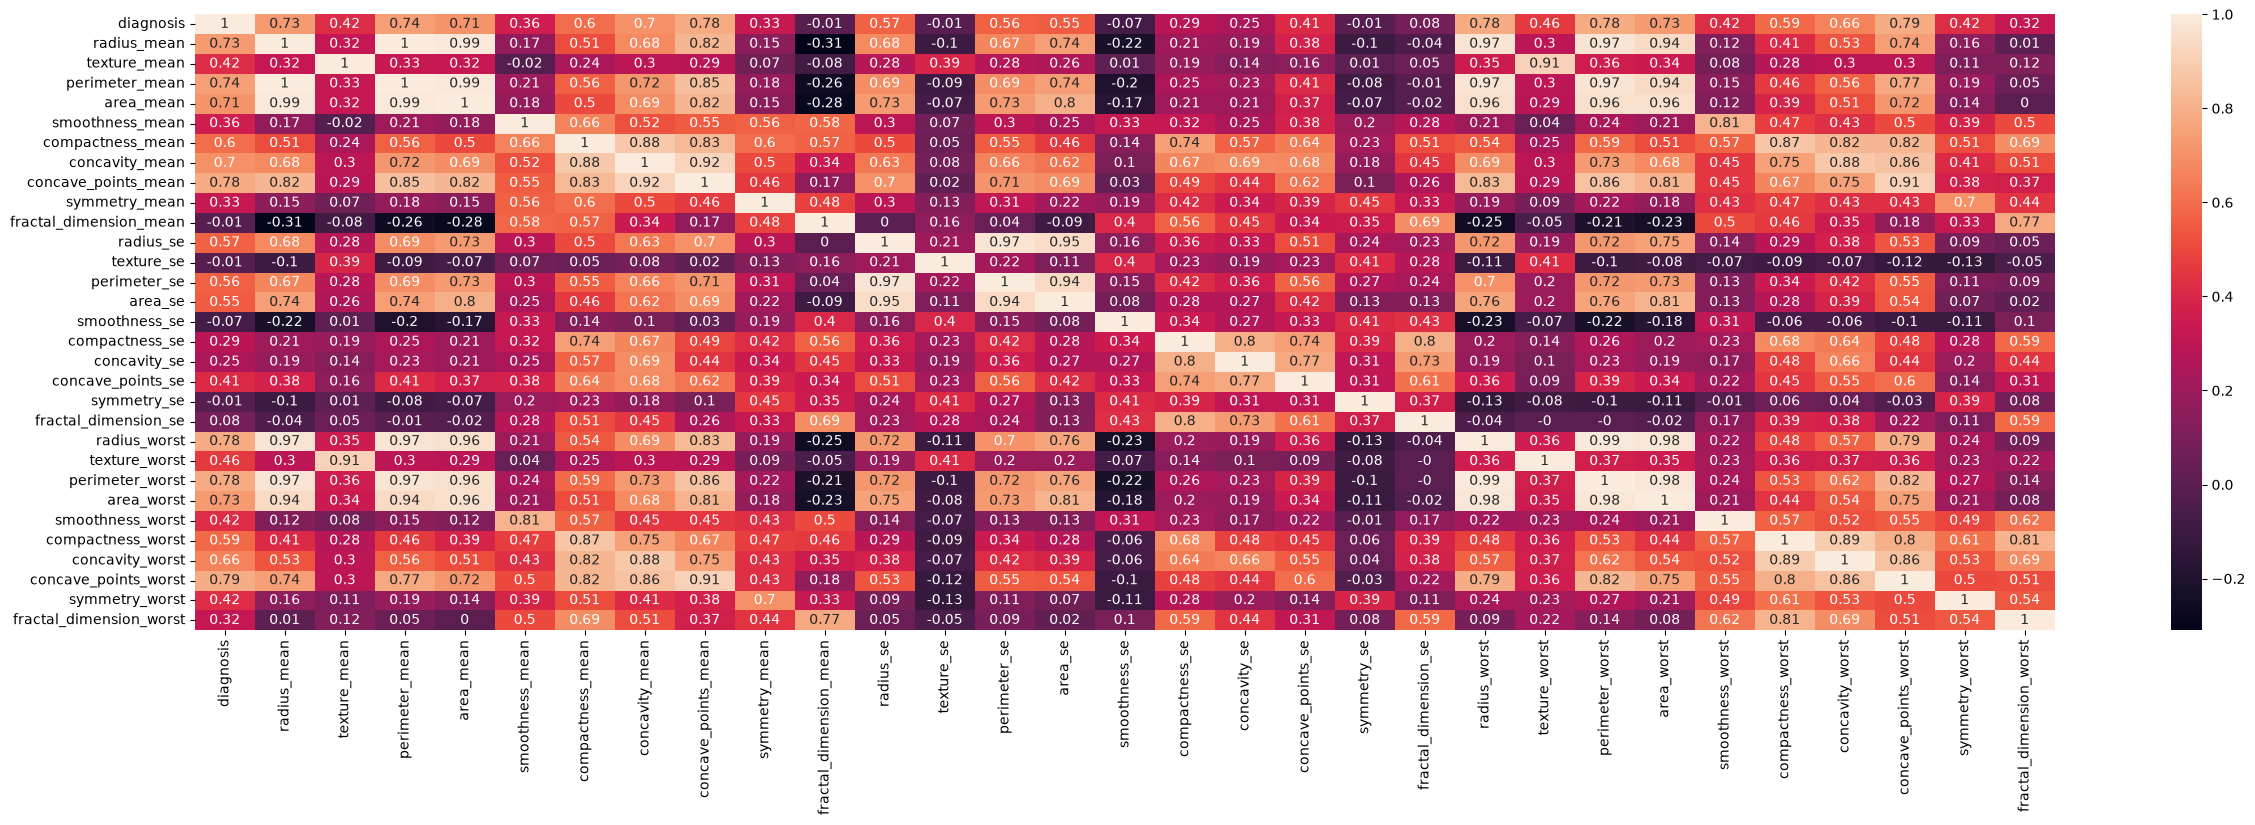

In [5]:
correlation_matrix = df.corr().round(2)

fig, ax = plt.subplots(figsize=(30, 8))
sb.heatmap(data=correlation_matrix, annot=True, ax=ax)
plt.show()

O mapa acima mostra blocos de variáveis fortemente correlacionadas entre si, por exemplo,
raio, perímetro e área aparecem quase idênticos. Esse padrão foi investigado detalhadamente
na seção de redundância mais abaixo.

In [6]:
df.describe().T[['mean', '50%', 'max', 'std']]

,mean,50%,max,std
diagnosis,0.372583,0.000000,1.00000,0.483918
radius_mean,14.127292,13.370000,28.11000,3.524049
texture_mean,19.289649,18.840000,39.28000,4.301036
perimeter_mean,91.969033,86.240000,188.50000,24.298981
area_mean,654.889104,551.100000,2501.00000,351.914129
smoothness_mean,0.096360,0.095870,0.16340,0.014064
compactness_mean,0.104341,0.092630,0.34540,0.052813
concavity_mean,0.088799,0.061540,0.42680,0.079720
concave_points_mean,0.048919,0.033500,0.20120,0.038803
symmetry_mean,0.181162,0.179200,0.30400,0.027414


#### Avaliação de outliers
A regra do IQR sinaliza 171 dos 569 exames (30%). Antes de removê-los, é preciso
verificar o que representam.


Exames com ao menos um outlier: 171 de 569
Malignos entre os COM outlier: 66.7%
Malignos entre os SEM outlier: 24.6%
Remover descartaria 114 dos 212 malignos (53.8%)

Acima do limite IQR de area_worst (1937): 0 benignos e 35 malignos (16.5% dos malignos)


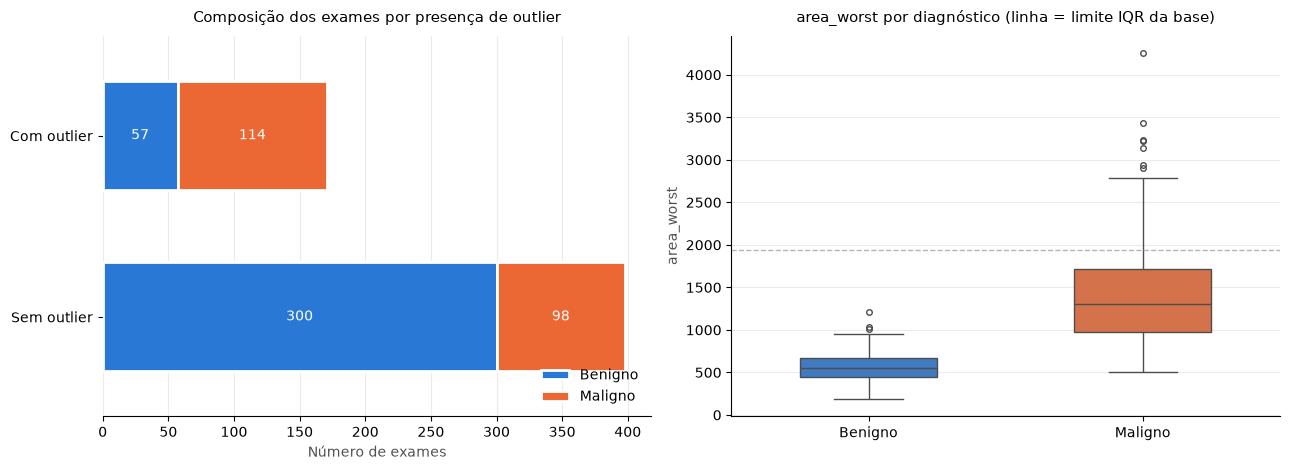

In [7]:
features = df.drop(columns=[TARGET])
q1, q3 = features.quantile(.25), features.quantile(.75)
iqr = q3 - q1
tem_outlier = ((features < q1 - 1.5*iqr) | (features > q3 + 1.5*iqr)).any(axis=1)

print(f"Exames com ao menos um outlier: {tem_outlier.sum()} de {len(df)}")
print(f"Malignos entre os COM outlier: {df.loc[tem_outlier, TARGET].mean():.1%}")
print(f"Malignos entre os SEM outlier: {df.loc[~tem_outlier, TARGET].mean():.1%}")
print(f"Remover descartaria {int(df.loc[tem_outlier, TARGET].sum())} dos "
      f"{int(df[TARGET].sum())} malignos "
      f"({df.loc[tem_outlier, TARGET].sum()/df[TARGET].sum():.1%})")

lim_area = q3['area_worst'] + 1.5 * iqr['area_worst']
acima = df['area_worst'] > lim_area
print(f"\nAcima do limite IQR de area_worst ({lim_area:.0f}): "
      f"{int((acima & (df[TARGET] == 0)).sum())} benignos e "
      f"{int((acima & (df[TARGET] == 1)).sum())} malignos "
      f"({(acima & (df[TARGET] == 1)).sum() / (df[TARGET] == 1).sum():.1%} dos malignos)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ct = pd.crosstab(tem_outlier, df[TARGET])
ct.index = ['Sem outlier', 'Com outlier']; ct.columns = ['Benigno', 'Maligno']
ct.plot(kind='barh', stacked=True, color=[AZUL, LARANJA], ax=axes[0],
        width=.6, edgecolor='white', linewidth=2)
for cont in axes[0].containers:
    axes[0].bar_label(cont, label_type='center', color='white', fontsize=10)
axes[0].set_title('Composição dos exames por presença de outlier', fontsize=11, pad=10)
axes[0].set_xlabel('Número de exames', color=TINTA2); axes[0].set_ylabel('')
axes[0].legend(frameon=False, loc='lower right'); axes[0].grid(axis='x', alpha=.25)
axes[0].set_axisbelow(True)
for s in ('top', 'right', 'left'): axes[0].spines[s].set_visible(False)

sb.boxplot(data=df, x=TARGET, y='area_worst', hue=TARGET, palette=[AZUL, LARANJA],
           legend=False, ax=axes[1], width=.5, fliersize=4)
axes[1].axhline(lim_area, ls='--', lw=1, color='#b5b4ad')
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['Benigno', 'Maligno'])
axes[1].set_title('area_worst por diagnóstico (linha = limite IQR da base)', fontsize=11, pad=10)
axes[1].set_xlabel(''); axes[1].set_ylabel('area_worst', color=TINTA2)
axes[1].grid(axis='y', alpha=.25); axes[1].set_axisbelow(True)
for s in ('top', 'right'): axes[1].spines[s].set_visible(False)
plt.tight_layout()

A proporção de malignos entre os exames sinalizados como outlier é muito maior que na base
como um todo. Isso indica que os valores extremos não são ruído de medição: são a
manifestação do próprio fenômeno que queremos detectar.

O boxplot de `area_worst` deixa isso concreto. O limite superior do IQR, calculado sobre a
base inteira, fica acima de três quartos dos tumores malignos — mas **nenhum tumor benigno
o ultrapassa**, enquanto 16,5% dos malignos ficam acima dele. Para essa variável, a regra
do IQR não está detectando erro de medição: está detectando malignidade.

A verificação abaixo testa a hipótese diretamente: treinamos o mesmo modelo com e sem as
linhas sinalizadas e comparamos o recall. Se os outliers fossem ruído, removê-los
melhoraria o resultado.

O teste é feito por validação cruzada **apenas no conjunto de treino** — a mesma divisão
usada no restante do notebook —, para que a decisão não seja tomada olhando o teste. Em
cada fold, os limites do IQR são calculados só com a parte de treino, os outliers são
removidos só dela, e a avaliação é feita na parte de validação completa, com outliers,
como seriam os exames reais.

In [ ]:
# mesma divisao usada adiante; a parte de teste e descartada aqui
_xtr, _, _ytr, _ = train_test_split(features, df[TARGET], test_size=0.2,
                                    random_state=RANDOM_STATE, stratify=df[TARGET])

base_outliers = Pipeline([('scaler', RobustScaler()), ('clf', SVC(kernel='rbf'))])
cv_outliers = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

# O que está sendo testado aqui é o impacto da remoção de outliers no recall do modelo
rec_com, rec_sem, removidos, malignos_removidos = [], [], [], []
for k, (tr, va) in enumerate(cv_outliers.split(_xtr, _ytr), start=1):
    xa, ya, xv, yv = _xtr.iloc[tr], _ytr.iloc[tr], _xtr.iloc[va], _ytr.iloc[va]
    a1, a3 = xa.quantile(.25), xa.quantile(.75)          # limites do IQR so do fold de treino
    fora = ((xa < a1 - 1.5 * (a3 - a1)) | (xa > a3 + 1.5 * (a3 - a1))).any(axis=1)

    rec_com.append(recall_score(yv, clone(base_outliers).fit(xa, ya).predict(xv)))
    rec_sem.append(recall_score(yv, clone(base_outliers).fit(xa[~fora], ya[~fora]).predict(xv)))
    removidos.append(int(fora.sum()))
    malignos_removidos.append(int(ya[fora].sum()))
    print(f'fold {k}: recall com todos {rec_com[-1]:.4f} | sem outliers {rec_sem[-1]:.4f} '
          f'| removidos {removidos[-1]} exames ({malignos_removidos[-1]} malignos de {int(ya.sum())})')

print(f'\nmédia com todos os exames: {np.mean(rec_com):.4f} ± {np.std(rec_com):.4f}')
print(f'média sem os outliers:     {np.mean(rec_sem):.4f} ± {np.std(rec_sem):.4f}')
print(f'folds em que a remoção piorou o recall: {sum(s < c for s, c in zip(rec_sem, rec_com))} de 5')

fold 1: recall com todos 0.9118 | sem outliers 0.7353 | removidos 108 exames (73 malignos de 136)
fold 2: recall com todos 1.0000 | sem outliers 1.0000 | removidos 110 exames (73 malignos de 136)
fold 3: recall com todos 0.9412 | sem outliers 0.9412 | removidos 100 exames (66 malignos de 136)
fold 4: recall com todos 0.9118 | sem outliers 0.7647 | removidos 107 exames (73 malignos de 136)
fold 5: recall com todos 0.9706 | sem outliers 0.7941 | removidos 111 exames (75 malignos de 136)

média com todos os exames: 0.9471 ± 0.0343
média sem os outliers:     0.8471 ± 0.1042
folds em que a remoção piorou o recall: 3 de 5


Remover os outliers derruba o recall médio de 0,947 para 0,847 e torna o modelo bem mais
instável: o desvio entre folds triplica, de ±0,034 para ±0,104. A remoção piora o recall
em 3 dos 5 folds. A cada fold ela descarta cerca de 107 exames, dos quais 72 malignos —
mais da metade dos malignos disponíveis para o treino.

**Decisão: mantemos todos os exames** e tratamos a assimetria das variáveis com
padronização.

Agora separamos as variáveis de entrada (`x`) do alvo (`y`) e dividimos a base em treino
(80%) e teste (20%), de forma estratificada.

In [ ]:
x = df.drop(columns=[TARGET]) # drop da coluna target do dataset: diagnosis
y = df[TARGET]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

> **Nota metodológica.** A partir daqui, o conjunto de teste (20%, 114 exames) fica
> reservado. Ele aparece em algumas etapas intermediárias deste notebook com finalidade
> didática, mas a seleção de modelo, hiperparâmetros, scaler e limiar é feita
> exclusivamente por validação cruzada sobre as 455 linhas de treino. O desempenho
> reportado como final é o da seção de avaliação final, no conjunto de teste.
>
> A divisão usa `stratify=y` para preservar a proporção de 62,7% benignos / 37,3%
> malignos nos dois conjuntos.

### Primeiros modelos: SVM e KNN

Começamos com dois classificadores, SVM (*Support Vector Machine*) e KNN (*K-Nearest
Neighbors*), ainda com hiperparâmetros escolhidos à mão. Criamos um pipeline que padroniza
os dados com o `RobustScaler` e aplica o SVM.

In [10]:
pipe = Pipeline([
    ('scaler', RobustScaler()),   # usa mediana e IQR → menos sensível a extremos
    ('clf', SVC(kernel='rbf')),
])
pipe.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave_points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"with_centering with_centering: bool, default=TrueIf `True`, center the data before scaling.This will cause :meth:`transform` to raise an exception when attemptedon sparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_scaling with_scaling: bool, default=TrueIf `True`, scale the data to interquartile range.",True
,"quantile_range quantile_range: tuple (q_min, q_max), 0.0 < q_min < q_max < 100.0, default=(25.0, 75.0)Quantile range used to calculate `scale_`. By default this is equal tothe IQR, i.e., `q_min` is the first quantile and `q_max` is the thirdquantile... versionadded:: 0.18","(25.0, ...)"


              precision    recall  f1-score   support

     Benigno       0.95      0.99      0.97        72
     Maligno       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



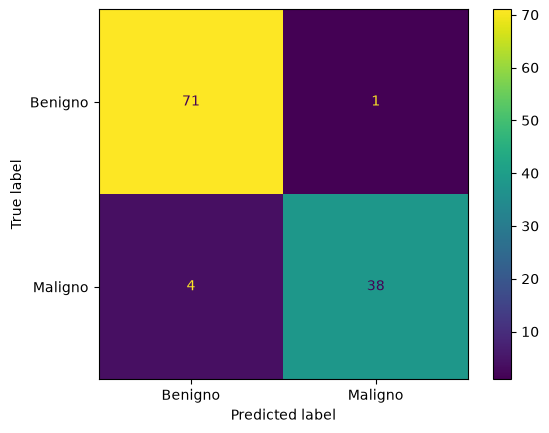

In [11]:
y_pred = pipe.predict(x_test)

print(classification_report(y_test, y_pred, target_names=['Benigno', 'Maligno']))
ConfusionMatrixDisplay.from_estimator(pipe, x_test, y_test,
                                      display_labels=['Benigno', 'Maligno'])
plt.show()

O `Pipeline` encadeia padronização e classificador num único objeto: no `fit`
ele aprende mediana e IQR apenas do treino e aplica; no `predict` apenas transforma,
com os parâmetros já aprendidos. Isso elimina por construção o risco de vazar
informação do teste para o treino.

Agora treinamos um KNN, com o mesmo `RobustScaler` para padronizar os dados. Primeiro
calculamos a taxa de erro para `k` de 1 a 9.

In [12]:
error = []

ks = range(1, 10)
for k in ks:
    knn = Pipeline([('scaler', RobustScaler()),
                    ('clf', KNeighborsClassifier(n_neighbors=k))])
    knn.fit(x_train, y_train)
    error.append(np.mean(knn.predict(x_test) != y_test))

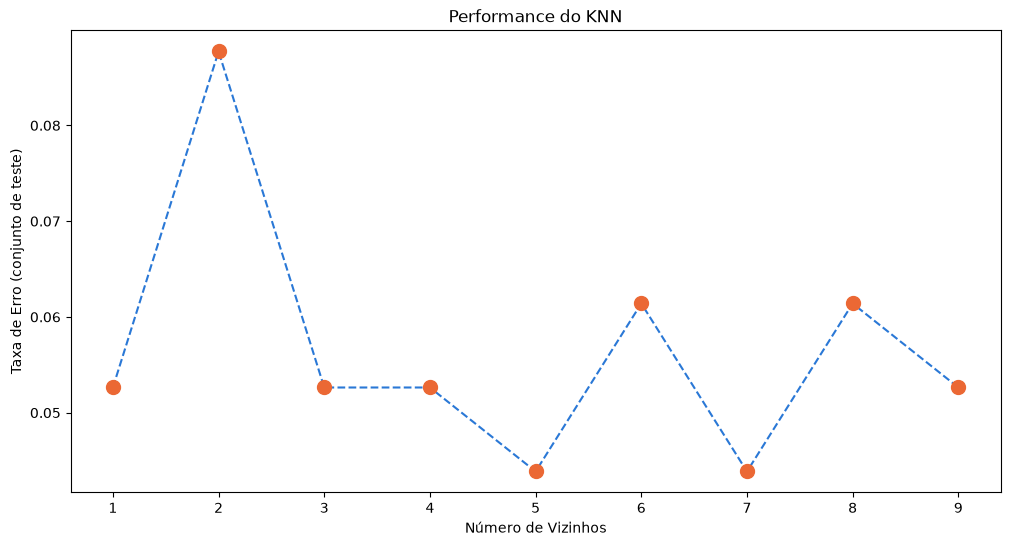

In [ ]:
# plotamos os erros
plt.figure(figsize=(12, 6))
plt.plot(ks, error, color=AZUL, linestyle='dashed', marker='o',
         markerfacecolor=LARANJA, markeredgecolor=LARANJA, markersize=10)
plt.xlabel('Número de Vizinhos')
plt.ylabel('Taxa de Erro (conjunto de teste)')
plt.title('Performance do KNN')
plt.show()

> A curva acima mede o erro no **conjunto de teste**, o que a torna uma exploração
> inicial e não um critério de escolha. Selecionar `k` olhando o teste faz o resultado
> final deixar de ser imparcial. A célula seguinte refaz a análise por validação cruzada
> sobre o treino, que é o procedimento correto.

Refazemos a escolha de `k` por validação cruzada estratificada (`StratifiedKFold`) sobre o
treino. Isso torna a estimativa de desempenho mais confiável e mantém o conjunto de teste
fora da decisão.

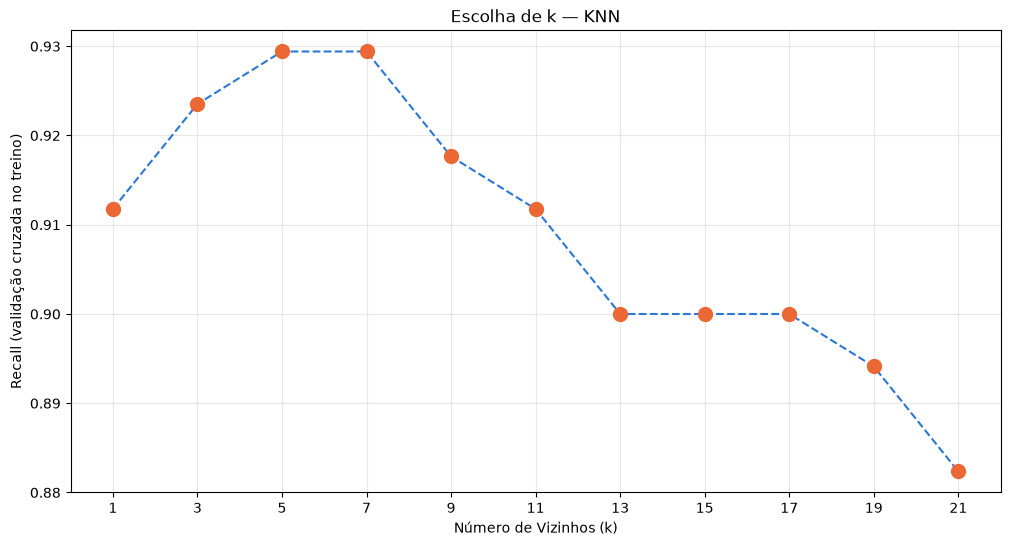

In [14]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
ks = range(1, 22, 2)
scores = []

for k in ks:
    p = Pipeline([('scaler', RobustScaler()),
                  ('clf', KNeighborsClassifier(n_neighbors=k))])
    scores.append(cross_val_score(p, x_train, y_train, cv=cv, scoring='recall').mean())

plt.figure(figsize=(12, 6))
plt.plot(ks, scores, color=AZUL, linestyle='dashed', marker='o',
         markerfacecolor=LARANJA, markeredgecolor=LARANJA, markersize=10)
plt.xlabel('Número de Vizinhos (k)')
plt.ylabel('Recall (validação cruzada no treino)')
plt.title('Escolha de k — KNN')
plt.xticks(list(ks))
plt.grid(alpha=.3)

A curva por validação cruzada aponta `k = 5` como o de melhor recall, empatado com
`k = 7`. Este valor será retestado mais adiante, com busca sistemática de hiperparâmetros
que também varia a métrica de distância e o scaler.

Treinamos o modelo com `k = 5` e o `RobustScaler`.

              precision    recall  f1-score   support

     Benigno       0.94      1.00      0.97        72
     Maligno       1.00      0.88      0.94        42

    accuracy                           0.96       114
   macro avg       0.97      0.94      0.95       114
weighted avg       0.96      0.96      0.96       114



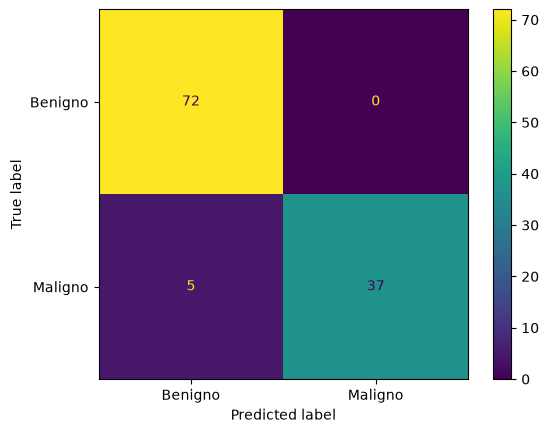

In [15]:
modelo_knn = Pipeline([('scaler', RobustScaler()),
                       ('clf', KNeighborsClassifier(n_neighbors=5))])
modelo_knn.fit(x_train, y_train)
y_predito = modelo_knn.predict(x_test)

print(classification_report(y_test, y_predito, target_names=['Benigno', 'Maligno']))
ConfusionMatrixDisplay.from_estimator(modelo_knn, x_test, y_test,
                                      display_labels=['Benigno', 'Maligno'])
plt.show()

### Regressão Logística e Árvore de Decisão

Além de SVM e KNN treinamos mais dois modelos com técnicas diferentes, ainda sem
ajuste de hiperparâmetros. A ideia é ter uma leitura inicial de cada abordagem
antes da busca sistemática:

- **Regressão Logística** - modelo linear e interpretável. Cada variável recebe um
  coeficiente, o que permite dizer o quanto ela empurra a previsão para maligno.
  É sensível a escala, então vai dentro de um `Pipeline` com padronização.
- **Árvore de Decisão** - modelo não linear baseado em regras de corte. Não precisa
  de padronização, porque cada corte olha uma variável isolada, mas tende a decorar
  o treino quando cresce sem limite.

In [16]:
modelos_iniciais = {
    'Regressão Logística': Pipeline([
        ('scaler', RobustScaler()),
        ('clf', LogisticRegression(max_iter=10000, random_state=RANDOM_STATE))]),
    'Árvore de Decisão': Pipeline([
        ('scaler', 'passthrough'),          # arvore nao precisa de escala
        ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
}

for nome, modelo in modelos_iniciais.items():
    modelo.fit(x_train, y_train)
    pred = modelo.predict(x_test)
    print(f'===== {nome} =====')
    print(classification_report(y_test, pred, target_names=['Benigno', 'Maligno']))

===== Regressão Logística =====
              precision    recall  f1-score   support

     Benigno       0.97      1.00      0.99        72
     Maligno       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

===== Árvore de Decisão =====
              precision    recall  f1-score   support

     Benigno       0.94      0.94      0.94        72
     Maligno       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



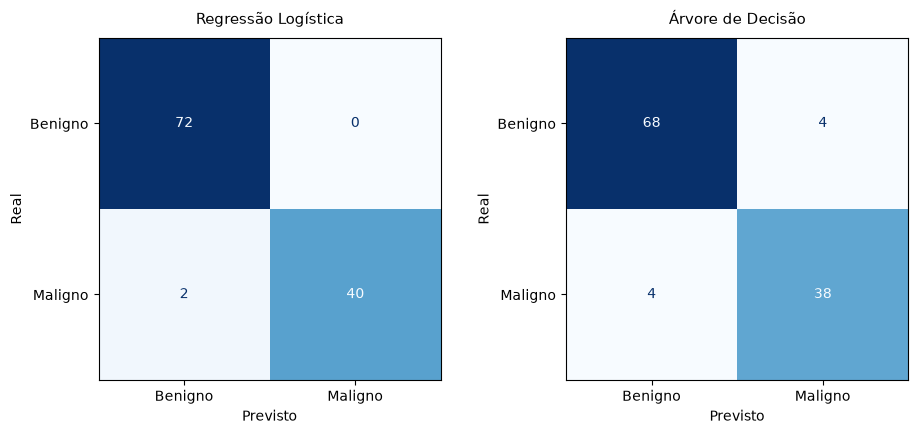

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.4))

for ax, (nome, modelo) in zip(axes, modelos_iniciais.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, x_test, y_test, display_labels=['Benigno', 'Maligno'],
        cmap='Blues', values_format='d', colorbar=False, ax=ax)
    ax.set_title(nome, fontsize=11, pad=10)
    ax.set_xlabel('Previsto'); ax.set_ylabel('Real')

plt.tight_layout()

A regressão logística supera a árvore com folga neste conjunto: 0,98 de
acurácia e recall 0,95 na classe maligna, contra 0,93 e 0,90 da árvore. A fronteira
entre benigno e maligno é aproximadamente linear, enquanto a
árvore sem poda cresce até separar o treino inteiro e generaliza pior.

Os quatro modelos vistos até aqui foram treinados com hiperparâmetros arbitrários e
avaliados em um único split de 114 exames. A próxima seção refaz a comparação de
forma sistemática.

## Aplicando validação cruzada de diferentes modelos com diferentes padronizações.

### Por que GridSearch com validação cruzada

Até aqui os hiperparâmetros foram escolhidos a mão. O `GridSearchCV` testa todas as
combinações de uma grade e mede cada uma por validação cruzada, escolhendo pelo
`refit='recall'`.

Três decisões desta célula merecem destaque:

- **O scaler entra na grade** (`'scaler': SCALERS`), ou seja, é tratado como mais um
  hiperparâmetro. A escolha deixa de ser argumento teórico e passa a ser resultado
  medido. Em princípio o scaler interage com o modelo — o `gamma='scale'` do SVC, por
  exemplo, depende da variância dos dados —, mas só testando se descobre quando isso faz
  diferença. A leitura da comparação, logo abaixo, mostra o resultado.
- **O `Pipeline` é reajustado em cada fold**, scaler incluído, de modo que nenhuma
  estatística de pré-processamento enxergue os dados de validação.
- **O `DummyClassifier` serve de piso.** Ele chuta sempre "benigno" e acerta ~63% dos
  casos, com recall zero. É a referência que mostra por que acurácia, sozinha, é uma
  métrica enganosa aqui.

In [18]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV

SCALERS = [StandardScaler(), RobustScaler(), MinMaxScaler()]

CONFIGS = {
    # referencia trivial: chuta sempre a classe majoritaria
    'Dummy': (DummyClassifier(strategy='most_frequent'),
              {'scaler': ['passthrough']}),

    'KNN': (KNeighborsClassifier(), {
        'scaler': SCALERS,
        'clf__n_neighbors': list(range(3, 22, 2)),
        'clf__weights': ['uniform', 'distance'],
        'clf__metric': ['euclidean', 'manhattan']}),

    'SVM': (SVC(random_state=RANDOM_STATE, probability=True), {
        'scaler': SCALERS,
        'clf__C': [0.1, 1, 10, 100],
        'clf__gamma': ['scale', 0.01, 0.1],
        'clf__kernel': ['rbf', 'linear']}),

    'LogisticRegression': (LogisticRegression(max_iter=10000, random_state=RANDOM_STATE), {
        'scaler': SCALERS,
        'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'clf__class_weight': [None, 'balanced']}),

    # arvores decidem por limiar em cada variavel isolada: escala nao altera o resultado
    'DecisionTree': (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'scaler': ['passthrough'],
        'clf__max_depth': [None, 3, 5, 10],
        'clf__min_samples_leaf': [1, 3, 5],
        'clf__criterion': ['gini', 'entropy'],
        'clf__class_weight': [None, 'balanced']}),

    'RandomForest': (RandomForestClassifier(random_state=RANDOM_STATE), {
        'scaler': ['passthrough'],
        'clf__n_estimators': [100, 300],
        'clf__max_depth': [None, 5, 10],
        'clf__min_samples_leaf': [1, 3]}),
}

METRICAS = {'accuracy': 'accuracy', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}


def compara_modelos(x, y, cv=None, refit='recall'):
    """Tuning + comparacao por validacao cruzada. Usar SEMPRE no conjunto de treino.

    Retorna (tabela_de_resultados, dict_com_os_melhores_pipelines).
    """
    cv = cv or StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    linhas, melhores = [], {}

    for nome, (modelo, grade) in CONFIGS.items():
        assert 'scaler' in grade, f"{nome}: defina 'scaler' na grade (use ['passthrough'])"

        gs = GridSearchCV(
            Pipeline([('scaler', 'passthrough'), ('clf', modelo)]),  # placeholder neutro
            grade, scoring=METRICAS, refit=refit, cv=cv, n_jobs=-1,
        ).fit(x, y)

        r, i = gs.cv_results_, gs.best_index_
        melhores[nome] = gs.best_estimator_
        linhas.append({
            'modelo': nome,
            **{m: f"{r['mean_test_' + m][i]:.4f} +- {r['std_test_' + m][i]:.3f}" for m in METRICAS},
            'combinacoes': len(r['params']),
        })
        # quantas combinacoes empatam no maximo, e com quais scalers
        empatadas = np.isclose(r['mean_test_' + refit], r['mean_test_' + refit].max())
        scalers_emp = sorted({p['scaler'] if isinstance(p['scaler'], str) else type(p['scaler']).__name__
                              for p, e in zip(r['params'], empatadas) if e})
        print(f"{nome}: {gs.best_params_}")
        print(f"   {int(empatadas.sum())} combinação(ões) empatada(s) no {refit} máximo; "
              f"scalers entre elas: {scalers_emp}")

    tabela = pd.DataFrame(linhas).sort_values(refit, ascending=False)
    return tabela, melhores


tabela, melhores = compara_modelos(x_train, y_train)
tabela

Dummy: {'scaler': 'passthrough'}
   1 combinação(ões) empatada(s) no recall máximo; scalers entre elas: ['passthrough']
KNN: {'clf__metric': 'manhattan', 'clf__n_neighbors': 3, 'clf__weights': 'uniform', 'scaler': MinMaxScaler()}
   2 combinação(ões) empatada(s) no recall máximo; scalers entre elas: ['MinMaxScaler']
SVM: {'clf__C': 10, 'clf__gamma': 'scale', 'clf__kernel': 'rbf', 'scaler': StandardScaler()}
   3 combinação(ões) empatada(s) no recall máximo; scalers entre elas: ['MinMaxScaler', 'RobustScaler', 'StandardScaler']
LogisticRegression: {'clf__C': 1, 'clf__class_weight': 'balanced', 'scaler': RobustScaler()}
   1 combinação(ões) empatada(s) no recall máximo; scalers entre elas: ['RobustScaler']
DecisionTree: {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'scaler': 'passthrough'}
   5 combinação(ões) empatada(s) no recall máximo; scalers entre elas: ['passthrough']
RandomForest: {'clf__max_depth': None, 'clf__

,modelo,accuracy,recall,f1,roc_auc,combinacoes
2,SVM,0.9758 +- 0.008,0.9647 +- 0.029,0.9674 +- 0.011,0.9935 +- 0.006,72
3,LogisticRegression,0.9714 +- 0.011,0.9647 +- 0.022,0.9619 +- 0.015,0.9953 +- 0.004,36
1,KNN,0.9802 +- 0.013,0.9529 +- 0.030,0.9728 +- 0.018,0.9838 +- 0.010,120
5,RandomForest,0.9604 +- 0.020,0.9471 +- 0.043,0.9468 +- 0.028,0.9880 +- 0.007,12
4,DecisionTree,0.9451 +- 0.020,0.9353 +- 0.043,0.9269 +- 0.027,0.9570 +- 0.016,48
0,Dummy,0.6264 +- 0.000,0.0000 +- 0.000,0.0000 +- 0.000,0.5000 +- 0.000,1


### Leitura da comparação

Na tabela abaixo, **apenas a métrica de decisão (recall) está destacada**. As demais
colunas aparecem sem ênfase de propósito: elas descrevem o comportamento dos modelos,
mas não orientam a escolha.

| modelo | acurácia | **recall (critério)** | f1 | AUC |
|---|---|---|---|---|
| SVM | 0,9758 ± 0,008 | **0,9647 ± 0,029** | 0,9674 | 0,9935 ± 0,006 |
| **Regressão Logística** | 0,9714 ± 0,011 | **0,9647 ± 0,022** | 0,9619 | 0,9953 ± 0,004 |
| KNN | 0,9802 ± 0,013 | 0,9529 ± 0,030 | 0,9728 | 0,9838 ± 0,010 |
| RandomForest | 0,9604 ± 0,020 | 0,9471 ± 0,043 | 0,9468 | 0,9880 ± 0,007 |
| DecisionTree | 0,9451 ± 0,020 | 0,9353 ± 0,043 | 0,9269 | 0,9570 ± 0,016 |
| Dummy | 0,6264 | 0,0000 | 0,0000 | 0,5000 |

**O KNN tem a maior acurácia, e ainda assim não é o modelo escolhido.** Ele lidera em
acurácia (0,9802) e em f1 (0,9728), mas fica em terceiro no recall (0,9529) — e o recall
da classe maligna é o critério definido no início deste notebook. Esse é um exemplo
direto de por que a métrica precisa ser escolhida *antes* de comparar: quem olhasse só a
acurácia escolheria o modelo que mais deixa passar tumores malignos.

**Há uma segunda razão, mais técnica, para descartar o KNN aqui.** Com `k=3`, o
`predict_proba` só consegue devolver quatro valores distintos (0, 1/3, 2/3 e 1). Isso
inviabiliza o ajuste de limiar que será feito mais adiante: mover o corte de 0,50
para 0,40 não altera nenhuma previsão, porque não existe probabilidade nesse intervalo.
É também o que explica a AUC mais baixa entre os três primeiros colocados — sua curva
ROC tem apenas quatro pontos. Um
modelo que não gradua confiança não responde ao mecanismo central da nossa estratégia.

**O modelo final é a Regressão Logística.** Ela empata com o SVM no critério principal
(recall 0,9647) e o supera nos demais aspectos relevantes:

- **AUC mais alta e mais estável**: 0,9953 ± 0,004 contra 0,9935 ± 0,006. A AUC mede a
  qualidade do ordenamento das probabilidades, que é exatamente o que o ajuste de limiar
  explora.
- **Interpretável por construção**: cada variável tem um coeficiente com sinal e
  magnitude, sem necessidade de aproximação para explicar a decisão.
- **Probabilidades nativas**: produz probabilidades diretamente, sem a calibração
  interna extra que o `SVC(probability=True)` exige — e essas probabilidades são a
  matéria-prima do ajuste de limiar.

Como a diferença de recall entre os dois está dentro da margem de ruído, o desempate se
apoia nesses critérios secundários, todos favoráveis à logística. A constante
`MODELO_ESCOLHIDO` concentra essa decisão. Trocar o valor para `'SVM'` recalcula o limiar
automaticamente, mas os textos da seção de interpretabilidade precisam ser revisados,
porque citam variáveis e valores específicos do modelo atual.

**O scaler importa — mas nem sempre.** Para o KNN e a regressão logística, uma única
combinação atinge o recall máximo, e o scaler dela (MinMax e Robust, respectivamente) é
uma escolha real. Para o SVM, os três scalers empatam: o `StandardScaler` aparece no
resultado apenas porque é o primeiro da lista, e o GridSearch desempata pela ordem da
grade. Testar o scaler junto com os hiperparâmetros continua valendo — foi justamente o
que mostrou que, para o KNN e a logística, ele faz diferença, e para o SVM não.

O mesmo cuidado vale para os hiperparâmetros da árvore e da random forest impressos
acima: há 5 e 4 combinações empatadas no recall máximo, respectivamente. Os valores
listados saem do desempate pela ordem da grade e não devem ser citados como "os
melhores" sem essa ressalva.

**O Dummy cumpre seu papel de piso**: 62,6% de acurácia chutando sempre "benigno", com
recall e AUC zerados. Qualquer modelo precisa superar essa linha para ter valor.

### Matrizes de confusão por validação cruzada

O `cross_val_predict` devolve, para cada uma das 455 linhas de treino, a previsão do
fold em que ela ficou **de fora** do treinamento. Toda previsão abaixo é
fora da amostra, não é o modelo acertando o que decorou.

A contagem absoluta de falsos negativos parece maior que a do conjunto de teste
simplesmente porque há 170 malignos aqui contra 42 lá; por isso o título mostra a
fração e não só o número.

Importante: a matriz agrega as previsões de 5 modelos (um por fold) e não
corresponde a um único classificador entregável. Ela serve para comparar o padrão de
erro de cada família.

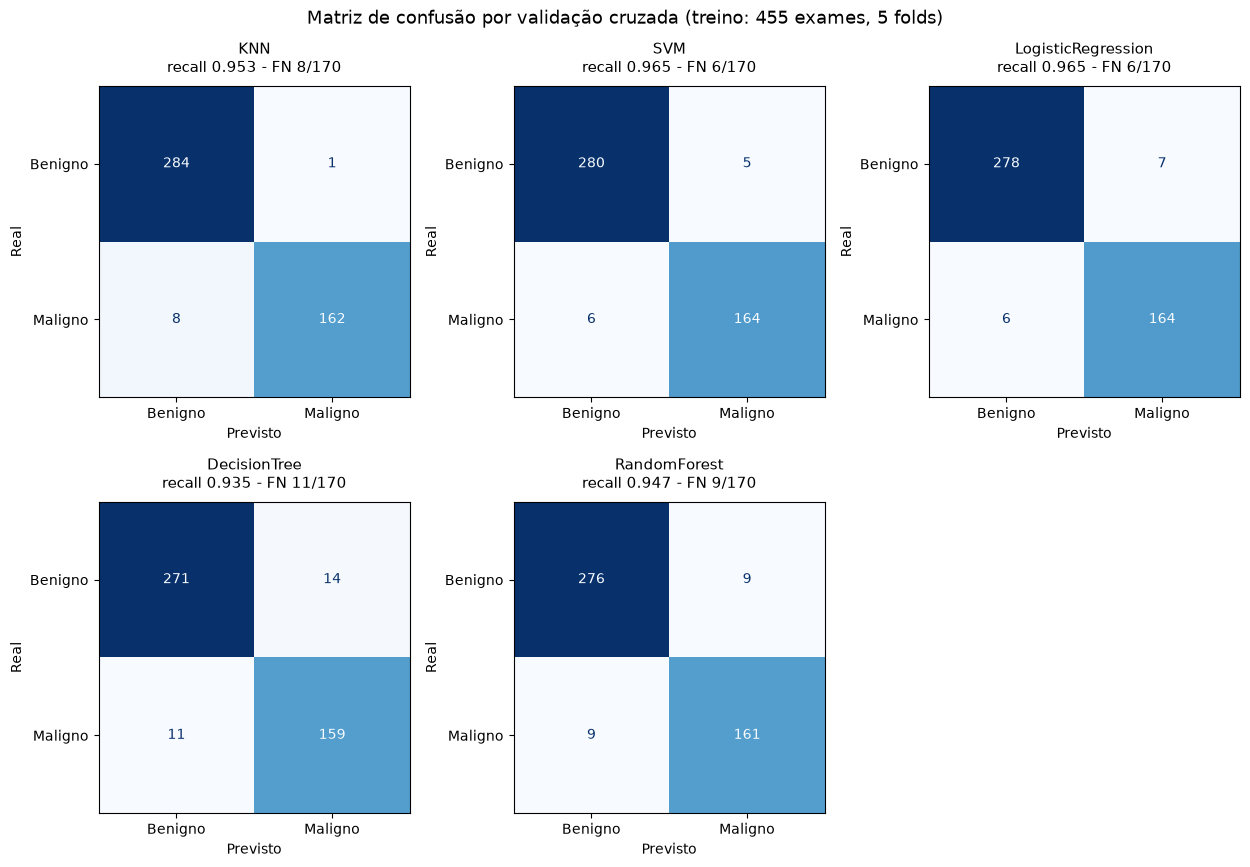

In [19]:
from sklearn.model_selection import cross_val_predict

ROTULOS = ['Benigno', 'Maligno']
modelos_plot = {k: v for k, v in melhores.items() if k != 'Dummy'}
n_malignos = int((y_train == 1).sum())

n_cols = 3
n_rows = int(np.ceil(len(modelos_plot) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4.4 * n_rows))
eixos = np.atleast_1d(axes).ravel()

for ax, (nome, modelo) in zip(eixos, modelos_plot.items()):
    y_cv = cross_val_predict(modelo, x_train, y_train, cv=cv)
    ConfusionMatrixDisplay.from_predictions(
        y_train, y_cv, display_labels=ROTULOS, cmap='Blues',
        values_format='d', colorbar=False, ax=ax)
    fn = ((y_train == 1) & (y_cv == 0)).sum()
    ax.set_title(f'{nome}\nrecall {recall_score(y_train, y_cv):.3f} - FN {fn}/{n_malignos}',
                 fontsize=11, pad=10)
    ax.set_xlabel('Previsto'); ax.set_ylabel('Real')

for ax in eixos[len(modelos_plot):]:
    ax.set_visible(False)

fig.suptitle(f'Matriz de confusão por validação cruzada (treino: {len(y_train)} exames, 5 folds)',
             fontsize=13)
plt.tight_layout()

### Ajuste do limiar de decisão

Todo classificador usa, por padrão, o corte de 0,5 sobre a probabilidade prevista — um
ponto neutro, que não leva em conta que aqui os dois erros têm custos muito diferentes.
Como o falso negativo é o erro grave, vale deslocar esse corte.

**A regra de decisão.** Escolhemos o limiar que minimiza o custo esperado
`CUSTO_FN × FN + FP`, em que `CUSTO_FN` é uma **premissa declarada**: quantos falsos
alarmes aceitamos para não deixar passar um câncer. Adotamos `CUSTO_FN = 10`. Num
contexto de triagem, um falso alarme leva a um exame adicional, enquanto um câncer não
detectado pode ter consequências graves. Quem discordar da premissa pode alterar a
constante: o limiar é recalculado automaticamente.

**Por que 20 repetições.** Uma única divisão em 5 folds exagera as diferenças entre
limiares próximos, que costumam se resumir a um ou dois exames. Repetimos a validação
cruzada com 20 embaralhamentos diferentes e usamos a média, sempre no conjunto de
treino, nunca no de teste.

**Por que a regra de 1 erro-padrão.** Quando a curva de custo é plana perto do mínimo,
as diferenças entre limiares vizinhos ficam dentro da margem de erro da estimativa e
escolher o mínimo exato seria escolher ruído. Seguimos a convenção da regra de 1
erro-padrão (Breiman et al., 1984): entre os limiares cujo custo médio está a até um
erro-padrão do mínimo, adotamos o **mais conservador**, isto é, o que gera menos falsos
alarmes.

A constante `MODELO_ESCOLHIDO` define qual pipeline segue para a avaliação final. Trocar
o modelo também recalcula o limiar automaticamente.

In [ ]:
MODELO_ESCOLHIDO = 'LogisticRegression'

# Premissa declarada: quantos falsos alarmes aceitamos para nao deixar passar um cancer.
# Alterar este valor recalcula o limiar automaticamente.
CUSTO_FN = 10

# limiares é igual ao intervalo de valores que vamos testar para o threshold de decisão
LIMIARES = np.round(np.arange(0.10, 0.61, 0.05), 2)
N_REPETICOES = 20

# validacao cruzada repetida com embaralhamentos diferentes, sempre no TREINO
fn_rep = np.zeros((N_REPETICOES, len(LIMIARES)))
fp_rep = np.zeros((N_REPETICOES, len(LIMIARES)))
for r in range(N_REPETICOES):
    prob_r = cross_val_predict(melhores[MODELO_ESCOLHIDO], x_train, y_train,
                               cv=StratifiedKFold(5, shuffle=True, random_state=r),
                               method='predict_proba')[:, 1]
    for j, t in enumerate(LIMIARES):
        pred = prob_r >= t
        fn_rep[r, j] = ((y_train == 1) & ~pred).sum()
        fp_rep[r, j] = ((y_train == 0) & pred).sum()

custo = CUSTO_FN * fn_rep + fp_rep
custo_medio = custo.mean(axis=0)
custo_ep = custo.std(axis=0, ddof=1) / np.sqrt(N_REPETICOES)

# regra de 1 erro-padrao: entre os limiares estatisticamente equivalentes ao minimo,
# adota o mais conservador (o maior limiar, que gera menos falsos alarmes)
j_min = int(np.argmin(custo_medio))
equivalentes = [j for j in range(len(LIMIARES)) if custo_medio[j] <= custo_medio[j_min] + custo_ep[j_min]]
LIMIAR = float(LIMIARES[max(equivalentes)])
LIMIAR_AGRESSIVO = float(LIMIARES[min(equivalentes)])

n_mal, n_ben = int((y_train == 1).sum()), int((y_train == 0).sum())
display(pd.DataFrame({
    'limiar': LIMIARES,
    'FN médio': fn_rep.mean(axis=0).round(2),
    'FP médio': fp_rep.mean(axis=0).round(2),
    'sensibilidade': (1 - fn_rep.mean(axis=0) / n_mal).round(4),
    'especificidade': (1 - fp_rep.mean(axis=0) / n_ben).round(4),
    'custo médio': custo_medio.round(2),
    'erro-padrão': custo_ep.round(2),
    'equivalente ao mínimo': ['sim' if j in equivalentes else '' for j in range(len(LIMIARES))],
}))

print(f'Custo mínimo em {LIMIARES[j_min]:.2f}. Equivalentes (até 1 erro-padrão): '
      f'{[float(LIMIARES[j]) for j in equivalentes]}')
print(f'Limiar adotado: {LIMIAR:.2f}  (o mais conservador entre os equivalentes)')

# sensibilidade: qual limiar a mesma regra adotaria com outras premissas de custo
def limiar_para(c_fn):
    cm = c_fn * fn_rep + fp_rep
    media, ep = cm.mean(axis=0), cm.std(axis=0, ddof=1) / np.sqrt(N_REPETICOES)
    jm = int(np.argmin(media))
    return float(LIMIARES[max(j for j in range(len(LIMIARES)) if media[j] <= media[jm] + ep[jm])])

print('\nSensibilidade à premissa de custo:')
for c_fn in [3, 5, 8, 10, 12, 15, 20]:
    marca = '  <- adotado' if c_fn == CUSTO_FN else ''
    print(f'   CUSTO_FN = {c_fn:2d}  ->  limiar {limiar_para(c_fn):.2f}{marca}')

,limiar,FN médio,FP médio,sensibilidade,especificidade,custo médio,erro-padrão,equivalente ao mínimo
0,0.10,1.90,39.60,0.9888,0.8611,58.60,0.99,
1,0.15,2.75,28.10,0.9838,0.9014,55.60,2.25,sim
2,0.20,3.60,21.10,0.9788,0.9260,57.10,1.83,sim
3,0.25,4.00,16.65,0.9765,0.9416,56.65,1.37,sim
4,0.30,4.40,13.60,0.9741,0.9523,57.60,1.20,sim
5,0.35,4.60,10.95,0.9729,0.9616,56.95,1.20,sim
6,0.40,4.90,8.95,0.9712,0.9686,57.95,1.25,
7,0.45,5.60,7.65,0.9671,0.9732,63.65,1.55,
8,0.50,6.55,6.50,0.9615,0.9772,72.00,2.27,
9,0.55,8.00,4.75,0.9529,0.9833,84.75,2.68,


Custo mínimo em 0.15. Equivalentes (até 1 erro-padrão): [0.15, 0.2, 0.25, 0.3, 0.35]
Limiar adotado: 0.35  (o mais conservador entre os equivalentes)

Sensibilidade à premissa de custo:
   CUSTO_FN =  3  ->  limiar 0.40
   CUSTO_FN =  5  ->  limiar 0.40
   CUSTO_FN =  8  ->  limiar 0.40
   CUSTO_FN = 10  ->  limiar 0.35  <- adotado
   CUSTO_FN = 12  ->  limiar 0.15
   CUSTO_FN = 15  ->  limiar 0.15
   CUSTO_FN = 20  ->  limiar 0.10


**Resultado.** Com `CUSTO_FN = 10` a curva de custo é praticamente plana: os limiares de
0,15 a 0,35 ficam todos a até um erro-padrão do mínimo, e a regra adota **0,35**, o mais
conservador deles.

Em relação ao corte padrão de 0,50, o limiar adotado reduz os falsos negativos de 6,55
para 4,60 em média (sensibilidade de 0,9615 para 0,9729), ao custo de cerca de 4,5 falsos
positivos a mais a cada 285 benignos (especificidade de 0,9772 para 0,9616).

A premissa é o ponto sensível desta decisão. Até `CUSTO_FN = 10` a regra fica entre 0,35
e 0,40; a partir de `CUSTO_FN = 12`, o limiar despenca para 0,15. Perto de 10, um pequeno
aumento no peso atribuído ao câncer não detectado muda o limiar bruscamente.

Uma ressalva técnica: as 20 repetições reaproveitam os mesmos dados, então não são
amostras independentes, e o erro-padrão calculado subestima a incerteza real. Na prática,
a faixa de limiares equivalentes é provavelmente ainda mais larga — e, com uma estimativa
mais conservadora da incerteza, a mesma regra poderia adotar 0,40. A escolha entre 0,35 e
0,40 está dentro da incerteza da própria análise.

## Redundância entre variáveis: PCA ou seleção?

Primeiro analisamos a correlação entre as colunas

Pares com correlação > 0,90: 21
Pares com correlação > 0,80: 44

radius_mean      perimeter_mean     0.9979
radius_worst     perimeter_worst    0.9937
radius_mean      area_mean          0.9874
perimeter_mean   area_mean          0.9865
radius_worst     area_worst         0.9840
perimeter_worst  area_worst         0.9776
radius_se        perimeter_se       0.9728
perimeter_mean   perimeter_worst    0.9704
radius_mean      radius_worst       0.9695
perimeter_mean   radius_worst       0.9695
radius_mean      perimeter_worst    0.9651
area_mean        radius_worst       0.9627
                 area_worst         0.9592
                 perimeter_worst    0.9591
radius_se        area_se            0.9518


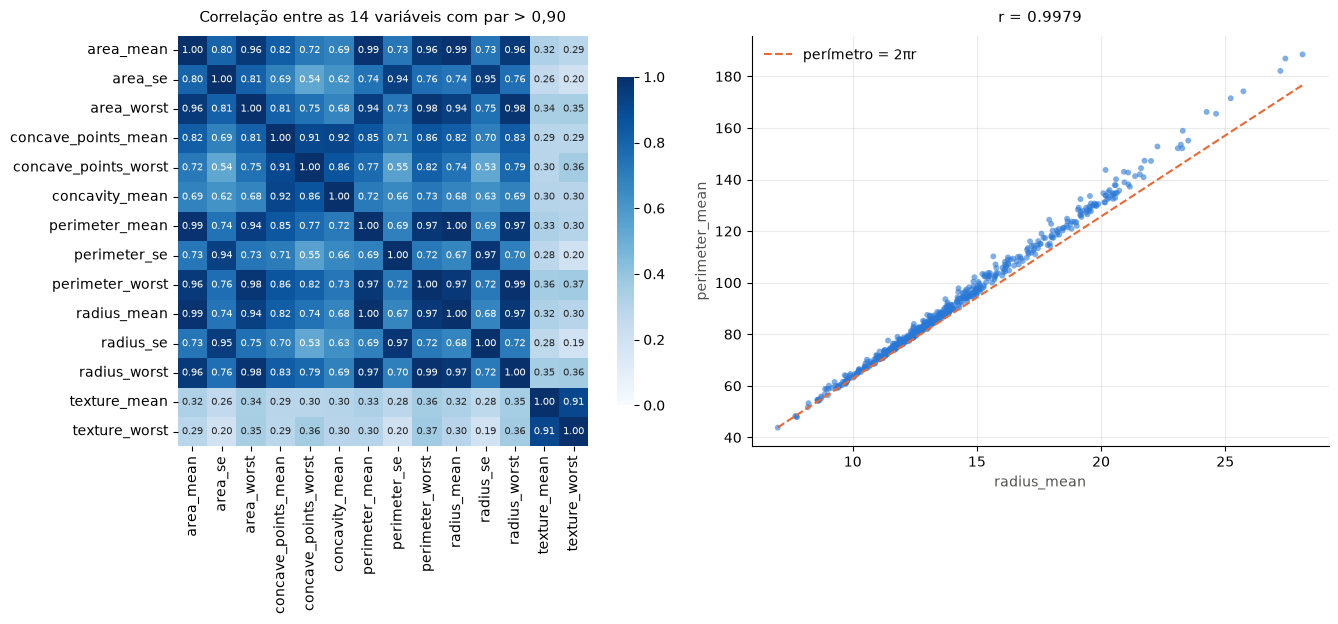

In [21]:
features = df.drop(columns=[TARGET])
cm_abs = features.corr().abs()
pares = cm_abs.where(np.triu(np.ones(cm_abs.shape), k=1).astype(bool)).stack()

print(f"Pares com correlação > 0,90: {(pares > 0.90).sum()}")
print(f"Pares com correlação > 0,80: {(pares > 0.80).sum()}\n")
print(pares[pares > 0.95].sort_values(ascending=False).round(4).to_string())

redundantes = sorted({c for par in pares[pares > 0.9].index for c in par})
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sb.heatmap(features[redundantes].corr(), annot=True, fmt='.2f', cmap='Blues',
           vmin=0, vmax=1, square=True, annot_kws={'size': 7},
           cbar_kws={'shrink': .8}, ax=axes[0])
axes[0].set_title(f'Correlação entre as {len(redundantes)} variáveis com par > 0,90',
                  fontsize=11, pad=10)

axes[1].scatter(df['radius_mean'], df['perimeter_mean'], s=18, alpha=.6,
                color=AZUL, edgecolor='none')
xx = np.linspace(df['radius_mean'].min(), df['radius_mean'].max(), 50)
axes[1].plot(xx, 2*np.pi*xx, ls='--', lw=1.5, color=LARANJA, label='perímetro = 2πr')
axes[1].set_xlabel('radius_mean', color=TINTA2); axes[1].set_ylabel('perimeter_mean', color=TINTA2)
axes[1].set_title(f"r = {df['radius_mean'].corr(df['perimeter_mean']):.4f}", fontsize=11, pad=10)
axes[1].legend(frameon=False); axes[1].grid(alpha=.25); axes[1].set_axisbelow(True)
for s in ('top', 'right'): axes[1].spines[s].set_visible(False)
plt.tight_layout()

A matriz de correlação revela pares quase idênticos. A relação **não é estatística, é
matemática**: perímetro e área são funções do raio, de modo que as três colunas medem a
mesma grandeza. O gráfico acima mostra os pontos caindo praticamente sobre a reta
`2*pi*r`.

Para modelos baseados em distância isso não é apenas ineficiência: informação duplicada
vira peso multiplicado no cálculo da distância, fazendo o "tamanho do núcleo" pesar
várias vezes mais que textura ou simetria.

Avaliar o VIF (Variance Inflation Factor) para identificar multicolinearidade entre as variáveis independentes. 
O VIF quantifica o quanto a variância de um coeficiente de regressão é inflacionada devido à colinearidade com outras variáveis. 

Um VIF alto (geralmente acima de 5 ou 10) indica que a variável está altamente correlacionada com outras variáveis, o que pode afetar a interpretação do modelo.

In [22]:
from sklearn.linear_model import LinearRegression

def calcula_vif(d):
    vifs = {}
    for c in d.columns:
        r2 = LinearRegression().fit(d.drop(columns=[c]), d[c]).score(d.drop(columns=[c]), d[c])
        vifs[c] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(vifs).sort_values(ascending=False)

# calculado no conjunto de treino, o mesmo usado para decidir quais colunas manter
vif_completa = calcula_vif(x_train)
print('VIF — 10 maiores (referência: VIF > 10 já indica multicolinearidade séria):')
print(vif_completa.head(10).round(1).to_string())

VIF — 10 maiores (referência: VIF > 10 já indica multicolinearidade séria):
perimeter_mean         4110.6
radius_mean            4041.8
radius_worst            799.6
perimeter_worst         419.6
area_mean               348.2
area_worst              326.1
radius_se                80.9
perimeter_se             78.8
concavity_mean           74.9
concave_points_mean      70.7


### Abordagem A — PCA: transformar em vez de remover

Há duas formas de lidar com a redundância que acabamos de documentar. A primeira é
**transformar**: o PCA projeta as 30 variáveis num novo conjunto de eixos ortogonais
(não correlacionados entre si por construção), ordenados pela variância que capturam.
A segunda, na seção seguinte, é **remover** variáveis redundantes mantendo as originais.

> **Todas as análises desta seção usam as 30 variáveis originais.** O PCA é aplicado
> antes de qualquer seleção e é independente dela — combinar as duas não faria sentido,
> já que são respostas alternativas ao mesmo problema.

Componentes para 95% da variância: 10
Componentes para 99% da variância: 17


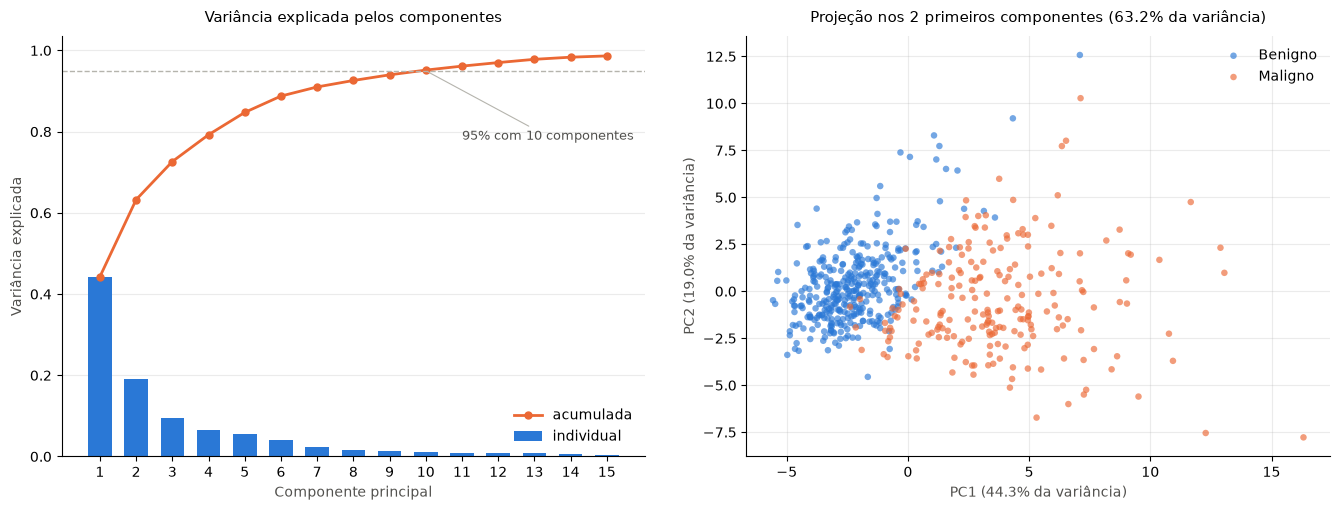

In [23]:
from sklearn.decomposition import PCA

# ATENCAO: esta celula e apenas DIAGNOSTICO VISUAL, por isso usa a base inteira.
# Para modelagem, o PCA entra como passo do Pipeline (celula seguinte), de modo
# que seja reajustado dentro de cada fold e nao veja os dados de validacao.
Xs = StandardScaler().fit_transform(features)
pca = PCA().fit(Xs)
var, acum = pca.explained_variance_ratio_, np.cumsum(pca.explained_variance_ratio_)
k95 = int(np.argmax(acum >= .95) + 1)
print(f"Componentes para 95% da variância: {k95}")
print(f"Componentes para 99% da variância: {int(np.argmax(acum >= .99) + 1)}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
n = 15
axes[0].bar(range(1, n + 1), var[:n], color=AZUL, width=.65, label='individual')
axes[0].plot(range(1, n + 1), acum[:n], color=LARANJA, marker='o', ms=5, lw=2, label='acumulada')
axes[0].axhline(.95, ls='--', lw=1, color='#b5b4ad')
axes[0].annotate(f'95% com {k95} componentes', xy=(k95, .95), xytext=(k95 + 1.0, .78),
                 color=TINTA2, fontsize=9,
                 arrowprops=dict(arrowstyle='-', color='#b5b4ad', lw=.8))
axes[0].set_xlabel('Componente principal', color=TINTA2)
axes[0].set_ylabel('Variância explicada', color=TINTA2)
axes[0].set_title('Variância explicada pelos componentes', fontsize=11, pad=10)
axes[0].set_xticks(range(1, n + 1)); axes[0].legend(frameon=False)
axes[0].grid(axis='y', alpha=.25); axes[0].set_axisbelow(True)
for s in ('top', 'right'): axes[0].spines[s].set_visible(False)

Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xs)
for v, cor, rot in [(0, AZUL, 'Benigno'), (1, LARANJA, 'Maligno')]:
    m = df[TARGET] == v
    axes[1].scatter(Z[m, 0], Z[m, 1], s=22, alpha=.65, color=cor, edgecolor='none', label=rot)
axes[1].set_xlabel(f'PC1 ({var[0]:.1%} da variância)', color=TINTA2)
axes[1].set_ylabel(f'PC2 ({var[1]:.1%} da variância)', color=TINTA2)
axes[1].set_title(f'Projeção nos 2 primeiros componentes ({acum[1]:.1%} da variância)',
                  fontsize=11, pad=10)
axes[1].legend(frameon=False); axes[1].grid(alpha=.25); axes[1].set_axisbelow(True)
for s in ('top', 'right'): axes[1].spines[s].set_visible(False)
plt.tight_layout()

O gráfico da esquerda mostra quanta variância cada componente principal carrega; o da
direita projeta os 569 exames nos dois primeiros componentes. A separação entre as
classes é visível, e a faixa de sobreposição no centro é onde se concentram os casos
difíceis de classificar — o que ajuda a entender por que nenhum modelo chega a 100% de
recall.

Aqui o PCA entra como **pré-processamento de verdade**: um passo do `Pipeline`,
entre o scaler e o classificador, reajustado dentro de cada fold. É a única forma
correta de usá-lo em modelagem: transformar a base inteira antes do split faria os
componentes serem calculados também com os dados de teste.

In [24]:
# Para cada modelo, a versão com PCA mantém o scaler e o classificador escolhidos pelo
# GridSearch: a única diferença entre as duas versões é o PCA.
def copia(passo):
    return passo if isinstance(passo, str) else clone(passo)

for nome in dict.fromkeys(['SVM', 'KNN', MODELO_ESCOLHIDO]):
    tunado = melhores[nome]
    print(f'{nome} sem PCA:'.ljust(30) + ' recall %.4f'
          % cross_val_score(tunado, x_train, y_train, cv=cv, scoring='recall').mean())
    for n_comp in [2, 5, 10, 0.95]:
        p = Pipeline([('scaler', copia(tunado.named_steps['scaler'])),
                      ('pca', PCA(n_components=n_comp, random_state=RANDOM_STATE)),
                      ('clf', copia(tunado.named_steps['clf']))])
        print(f'{nome} + PCA({n_comp}):'.ljust(30) + ' recall %.4f'
              % cross_val_score(p, x_train, y_train, cv=cv, scoring='recall').mean())
    print()

SVM sem PCA:                   recall 0.9647
SVM + PCA(2):                  recall 0.8588
SVM + PCA(5):                  recall 0.9529
SVM + PCA(10):                 recall 0.9647
SVM + PCA(0.95):               recall 0.9647

KNN sem PCA:                   recall 0.9529
KNN + PCA(2):                  recall 0.8706
KNN + PCA(5):                  recall 0.9294
KNN + PCA(10):                 recall 0.9353
KNN + PCA(0.95):               recall 0.9294

LogisticRegression sem PCA:    recall 0.9647
LogisticRegression + PCA(2):   recall 0.9059
LogisticRegression + PCA(5):   recall 0.9588
LogisticRegression + PCA(10):  recall 0.9647
LogisticRegression + PCA(0.95): recall 0.9647



O PCA não melhorou o desempenho de nenhum modelo. Com 10 componentes ou mais, o SVM e a
regressão logística mantêm exatamente o mesmo recall; com menos componentes, todos perdem.
O KNN piora em qualquer configuração (de 0,9529 para 0,9353 com 10 componentes). A
comparação mantém o scaler escolhido pelo GridSearch para cada modelo, de modo que a única
diferença entre as duas versões é o PCA.

Optamos por manter as variáveis originais, que preservam a interpretabilidade clínica:
cada componente principal é uma combinação linear das 30 medidas e não corresponde a
nenhuma grandeza observável no exame. Essa limitação é decisiva num problema de
diagnóstico, onde explicar a decisão importa tanto quanto acertá-la.

Resta testar a segunda abordagem: remover as variáveis redundantes em vez de
transformá-las.

### Abordagem B — seleção: remover variáveis redundantes

A alternativa ao PCA é descartar colunas e manter as demais intactas, preservando a
interpretabilidade clínica de cada medida.

A seleção abaixo mantém, de cada grupo de variáveis correlacionadas acima de 0,90,
apenas aquela com maior correlação com o alvo; em seguida descarta as de correlação
muito baixa com o diagnóstico.

O cálculo usa `x_train` e `y_train`, nunca a base completa: decidir quais colunas ficam
olhando o conjunto de teste também é vazamento.

In [ ]:
X_red = x_train   # selecao calculada so no treino
Y_red = y_train

# mantem apenas as colunas mais correlacionadas com a coluna target
corr_y = X_red.corrwith(Y_red).abs()
cm = X_red.corr().abs()

# remove redundancia, como area/perimetro
keep = []
for col in corr_y.sort_values(ascending=False).index:
    if all(cm.loc[col, k] < 0.9 for k in keep):
        keep.append(col)

In [26]:
# remove colunas de baixa correlacao com a coluna target
keep = [k for k in keep if corr_y[k] > 0.2]
keep

['concave_points_worst',
 'perimeter_worst',
 'concavity_mean',
 'concavity_worst',
 'compactness_mean',
 'compactness_worst',
 'radius_se',
 'texture_worst',
 'smoothness_worst',
 'symmetry_worst',
 'concave_points_se',
 'smoothness_mean',
 'symmetry_mean',
 'fractal_dimension_worst',
 'compactness_se',
 'concavity_se']

In [27]:
vif_selecao = calcula_vif(x_train[keep])
print(f"VIF máximo: {vif_completa.max():.1f} -> {vif_selecao.max():.1f}\n")
print('VIF das variáveis selecionadas — 5 maiores:')
print(vif_selecao.head(5).round(1).to_string())

VIF máximo: 4110.6 -> 27.3

VIF das variáveis selecionadas — 5 maiores:
compactness_worst       27.3
concavity_mean          26.1
concavity_worst         24.5
concave_points_worst    22.1
compactness_mean        21.8


A queda do VIF máximo mede o efeito da seleção sobre a multicolinearidade: o maior valor
cai de mais de 4.000 para menos de 30.

Mas o conjunto selecionado **continua acima do limite de 10**. A seleção eliminou a
redundância geométrica entre raio, perímetro e área, que era a mais grave, mas as medidas
de concavidade e compacidade seguem correlacionadas entre si. A multicolinearidade foi
reduzida em duas ordens de grandeza, não eliminada.

Para comparar de forma justa, a análise com as variáveis selecionadas reaproveita
exatamente a mesma divisão treino/teste usada até aqui, apenas recortando as colunas,
e o mesmo pipeline do modelo final.

In [28]:
# reaproveita a MESMA divisao treino/teste, apenas recortando as colunas selecionadas
x_red_train, x_red_test = x_train[keep], x_test[keep]
y_red_train, y_red_test = y_train, y_test

print(f'Treino: {x_red_train.shape} | Teste: {x_red_test.shape}')

Treino: (455, 16) | Teste: (114, 16)


In [29]:
# mesmo pipeline do modelo final (scaler e hiperparametros), treinado so com as 16 colunas
modelo_red = clone(melhores[MODELO_ESCOLHIDO]).fit(x_red_train, y_red_train)
modelo_red

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['concave_points_worst','perimeter_worst','concavity_mean',..., 'fractal_dimension_worst','compactness_se','concavity_se']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"with_centering with_centering: bool, default=TrueIf `True`, center the data before scaling.This will cause :meth:`transform` to raise an exception when attemptedon sparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_scaling with_scaling: bool, default=TrueIf `True`, scale the data to interquartile range.",True
,"quantile_range quantile_range: tuple (q_min, q_max), 0.0 < q_min < q_max < 100.0, default=(25.0, 75.0)Quantile range used to calculate `scale_`. By default this is equal tothe IQR, i.e., `q_min` is the first quantile and `q_max` is the thirdquantile... versionadded:: 0.18","(25.0, ...)"


              precision    recall  f1-score   support

     Benigno       0.97      0.99      0.98        72
     Maligno       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



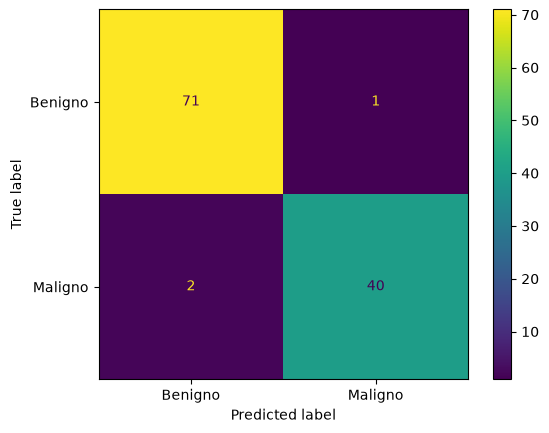

In [30]:
y_pred_red = modelo_red.predict(x_red_test)

print(classification_report(y_red_test, y_pred_red, target_names=['Benigno', 'Maligno']))
ConfusionMatrixDisplay.from_estimator(modelo_red, x_red_test, y_red_test,
                                      display_labels=['Benigno', 'Maligno'])
plt.show()

In [31]:
for nome, cols in [('30 variáveis', list(x_train.columns)), (f'{len(keep)} variáveis', keep)]:
    modelo = clone(melhores[MODELO_ESCOLHIDO])
    acc = cross_val_score(modelo, x_train[cols], y_train, cv=cv, scoring='accuracy')
    rec = cross_val_score(modelo, x_train[cols], y_train, cv=cv, scoring='recall')
    print(f'{nome}: acurácia {acc.mean():.4f} +- {acc.std():.4f} | '
          f'recall {rec.mean():.4f} +- {rec.std():.4f}')

30 variáveis: acurácia 0.9714 +- 0.0112 | recall 0.9647 +- 0.0220
16 variáveis: acurácia 0.9736 +- 0.0149 | recall 0.9529 +- 0.0353


A comparação usa o mesmo pipeline do modelo final (regressão logística tunada), para que
a conclusão valha para o modelo que de fato será entregue.

Com 16 variáveis, a acurácia em validação cruzada fica praticamente igual (0,9736 contra
0,9714) e o **recall cai de 0,9647 para 0,9529**. A queda está dentro da margem de ruído
(±0,022 e ±0,035), mas aponta na direção contrária ao critério que orienta o notebook.

**Decisão: o modelo final usa as 30 variáveis.** A seleção não melhora o recall, e o
ganho de interpretabilidade que ela traria já é obtido de outra forma: os coeficientes da
regressão logística e os valores SHAP, na seção de interpretabilidade, explicam a
contribuição de cada uma das 30 medidas. A seleção fica registrada como alternativa viável
caso o custo de coleta das variáveis passe a pesar.

## Avaliação final do conjunto de teste

### Resultado final

O modelo escolhido pela validação cruzada é aplicado uma única vez ao conjunto de teste,
com o limiar definido na seção de ajuste do limiar. Este é o número que o relatório deve
reportar como desempenho esperado em dados novos.

Modelo: LogisticRegression | limiar: 0.35
              precision    recall  f1-score   support

     Benigno       0.97      0.99      0.98        72
     Maligno       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



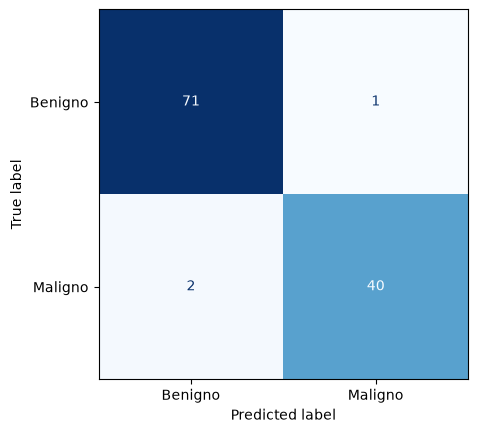

In [32]:
modelo_final = melhores[MODELO_ESCOLHIDO]

prob_teste = modelo_final.predict_proba(x_test)[:, 1]
y_pred_final = (prob_teste >= LIMIAR).astype(int)

print(f'Modelo: {MODELO_ESCOLHIDO} | limiar: {LIMIAR}')
print(classification_report(y_test, y_pred_final, target_names=ROTULOS))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=ROTULOS,
                                        cmap='Blues', values_format='d', colorbar=False)
plt.show()

In [33]:
from scipy.stats import norm

def intervalo_wilson(acertos, total, confianca=0.95):
    """Intervalo de confiança de Wilson para uma proporção (adequado a amostras pequenas)."""
    z = norm.ppf(1 - (1 - confianca) / 2)
    p = acertos / total
    centro = (p + z**2 / (2 * total)) / (1 + z**2 / total)
    meia = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return centro - meia, centro + meia

vp = int(((y_test == 1) & (y_pred_final == 1)).sum())
n_malignos_teste = int((y_test == 1).sum())
n_alarmes = int((y_pred_final == 1).sum())

lo_r, hi_r = intervalo_wilson(vp, n_malignos_teste)
lo_p, hi_p = intervalo_wilson(vp, n_alarmes)
print(f'Recall no teste:   {vp / n_malignos_teste:.3f} ({vp} de {n_malignos_teste} malignos) '
      f'| IC 95%: [{lo_r:.3f}, {hi_r:.3f}]')
print(f'Precisão no teste: {vp / n_alarmes:.3f} ({vp} de {n_alarmes} alarmes) '
      f'| IC 95%: [{lo_p:.3f}, {hi_p:.3f}]')

# a mesma métrica estimada por validação cruzada, no mesmo limiar (20 repetições, 170 malignos)
j_lim = max(equivalentes)
print(f'\nSensibilidade por validação cruzada no limiar {LIMIAR:g}: '
      f'{1 - fn_rep.mean(axis=0)[j_lim] / n_mal:.3f} (média de {N_REPETICOES} repetições, {n_mal} malignos)')

Recall no teste:   0.952 (40 de 42 malignos) | IC 95%: [0.842, 0.987]
Precisão no teste: 0.976 (40 de 41 alarmes) | IC 95%: [0.874, 0.996]

Sensibilidade por validação cruzada no limiar 0.35: 0.973 (média de 20 repetições, 170 malignos)


**A incerteza do resultado.** O conjunto de teste tem só 42 malignos, e cada caso vale 2,4
pontos de recall. O intervalo de 95% para o recall no teste vai de 0,84 a 0,99: o valor
pontual de 0,952 não deve ser reportado sozinho.

A estimativa por validação cruzada no mesmo limiar, feita sobre 170 malignos e 20
repetições, é mais estável — sensibilidade de 0,973 — e cai dentro desse intervalo. No
relatório vale citar os dois: o teste como confirmação independente e a validação cruzada
como a estimativa mais precisa.

A curva ROC percorre todos os limiares possíveis: cada ponto é um par
(falsos positivos, verdadeiros positivos). A AUC resume a curva em um número, a
probabilidade de o modelo atribuir score maior a um maligno sorteado ao acaso do que
a um benigno. O círculo marca o ponto de operação do
modelo final, no limiar adotado.

Curvas em degraus largos indicam modelos que graduam pouco a confiança: um KNN com
`k=3`, por exemplo, só pode devolver quatro probabilidades distintas.

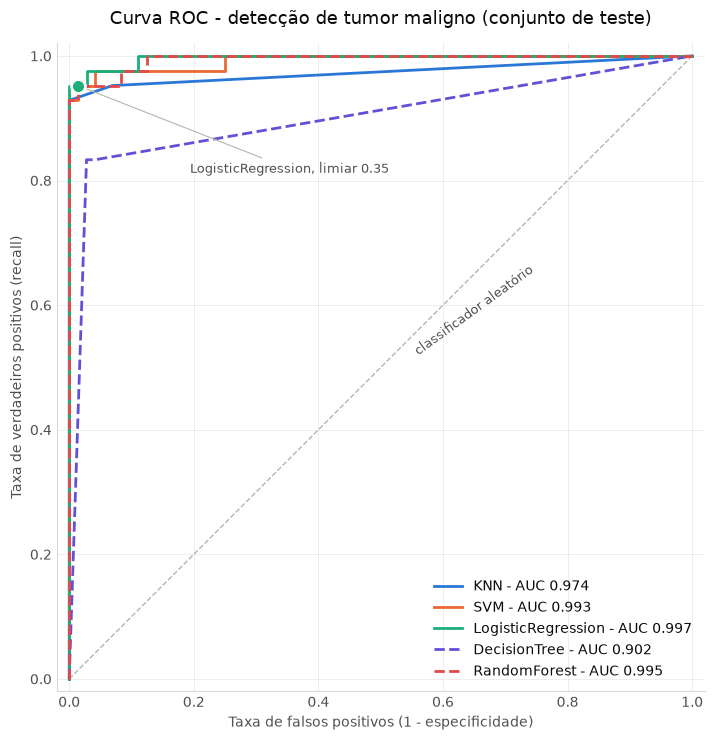

In [34]:
from sklearn.metrics import roc_curve, roc_auc_score

# cor + estilo de linha: a identidade da curva nunca depende so da cor
ESTILOS = [(AZUL, '-'), (LARANJA, '-'), (VERDE, '-'),
           (VIOLETA, '--'), (VERMELHO, '--'), (TINTA2, ':')]

assert len(modelos_plot) <= len(ESTILOS), 'há mais modelos do que estilos de linha'

fig, ax = plt.subplots(figsize=(7.5, 7.5))

for (nome, modelo), (cor, traco) in zip(modelos_plot.items(), ESTILOS):
    prob = modelo.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, color=cor, linestyle=traco, linewidth=2, label=f'{nome} - AUC {auc:.3f}')
    if nome == MODELO_ESCOLHIDO:
        cor_final = cor

# ponto de operacao do modelo final, calculado a partir das previsoes no limiar adotado
fpr_final = ((y_test == 0) & (y_pred_final == 1)).sum() / (y_test == 0).sum()
tpr_final = ((y_test == 1) & (y_pred_final == 1)).sum() / (y_test == 1).sum()
ax.plot(fpr_final, tpr_final, 'o', color=cor_final, markersize=10,
        markeredgecolor='white', markeredgewidth=2, zorder=5)
ax.annotate(f'{MODELO_ESCOLHIDO}, limiar {LIMIAR:g}', xy=(fpr_final, tpr_final),
            xytext=(fpr_final + 0.18, tpr_final - 0.14), color=TINTA2, fontsize=9,
            arrowprops=dict(arrowstyle='-', color='#b5b4ad', lw=.8))

ax.plot([0, 1], [0, 1], linestyle='--', linewidth=1, color='#b5b4ad', zorder=1)
ax.annotate('classificador aleatório', xy=(0.55, 0.52), color=TINTA2, fontsize=9, rotation=36)

ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect('equal')
ax.set_xlabel('Taxa de falsos positivos (1 - especificidade)', color=TINTA2)
ax.set_ylabel('Taxa de verdadeiros positivos (recall)', color=TINTA2)
ax.set_title('Curva ROC - detecção de tumor maligno (conjunto de teste)',
             color=TINTA, fontsize=13, pad=14)
ax.grid(alpha=0.25, linewidth=0.6); ax.set_axisbelow(True)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
for s in ('left', 'bottom'): ax.spines[s].set_color('#d9d8d2')
ax.tick_params(colors=TINTA2, length=0)
ax.legend(loc='lower right', frameon=False, labelcolor=TINTA)
plt.tight_layout()
plt.show()

Se os erros de dois modelos ocorrem nos **mesmos** exames, combiná-los não traz ganho; se
ocorrem em exames diferentes, há espaço para um comitê de votação.

A verificação abaixo compara os três modelos mais fortes no corte padrão de 0,5 —
condição igual para todos — e mostra também os erros do modelo final no limiar adotado.

In [35]:
modelos_fn = ['SVM', 'KNN', 'LogisticRegression']
fn_por_modelo = {n: set(y_test.index[(y_test == 1) & (melhores[n].predict(x_test) == 0)])
                 for n in modelos_fn}

for n in modelos_fn:
    print(f'{n:20s} (corte 0,5): {sorted(fn_por_modelo[n])}')
print(f'{"perdidos por todos":20s}            : {sorted(set.intersection(*fn_por_modelo.values()))}')
print(f'{"perdidos por algum":20s}            : {sorted(set.union(*fn_por_modelo.values()))}')

fn_final = set(y_test.index[(y_test == 1) & (y_pred_final == 0)])
print(f'\nModelo final ({MODELO_ESCOLHIDO}, limiar {LIMIAR:g}): {sorted(fn_final)}')

SVM                  (corte 0,5): [73, 99, 205]
KNN                  (corte 0,5): [73, 205, 385]
LogisticRegression   (corte 0,5): [73, 190]
perdidos por todos              : [73]
perdidos por algum              : [73, 99, 190, 205, 385]

Modelo final (LogisticRegression, limiar 0.35): [73, 190]


Os erros divergem em parte: cada modelo perde algum exame que os outros acertam, o que
indica espaço para um comitê de votação — fica registrado como extensão possível.

O exame 73 é perdido pelos três modelos e continua perdido pelo modelo final mesmo com o
limiar ajustado. É o caso genuinamente difícil, que reaparece na seção de
interpretabilidade com probabilidade prevista de apenas 0,105.

## Interpretabilidade: quais variáveis o modelo usa

> Os resultados desta seção são **específicos do modelo em `MODELO_ESCOLHIDO`**. Trocar
> o modelo exige revisar também os textos interpretativos abaixo, que citam variáveis e
> valores concretos.

Um modelo de apoio ao diagnóstico precisa ser auditável: não basta acertar, é preciso
poder explicar em que o acerto se baseia. O **SHAP** (SHapley Additive exPlanations)
atribui a cada variável, em cada exame, quanto ela empurrou a previsão para maligno ou
para benigno.

Usamos o **`KernelExplainer`**, que é agnóstico ao modelo: ele não precisa conhecer o
funcionamento interno, apenas conseguir chamá-lo. Existe um `LinearExplainer` mais rápido
e específico para modelos lineares, que serviria para a regressão logística escolhida,
mas o `KernelExplainer` mantém esta seção válida caso `MODELO_ESCOLHIDO` seja trocado por
SVM ou RandomForest, e o custo aqui é de poucos segundos.

Como passamos o `Pipeline` inteiro, a padronização acontece dentro da caixa-preta e as
explicações saem na **escala original** das variáveis: em unidades de textura, área e
perímetro, e não em desvios padrão.

O custo é O(n_fundo × n_amostras), por isso o conjunto de referência é comprimido com
`shap.kmeans` antes de explicar.

SHAP values calculados: 114 exames x 30 variáveis


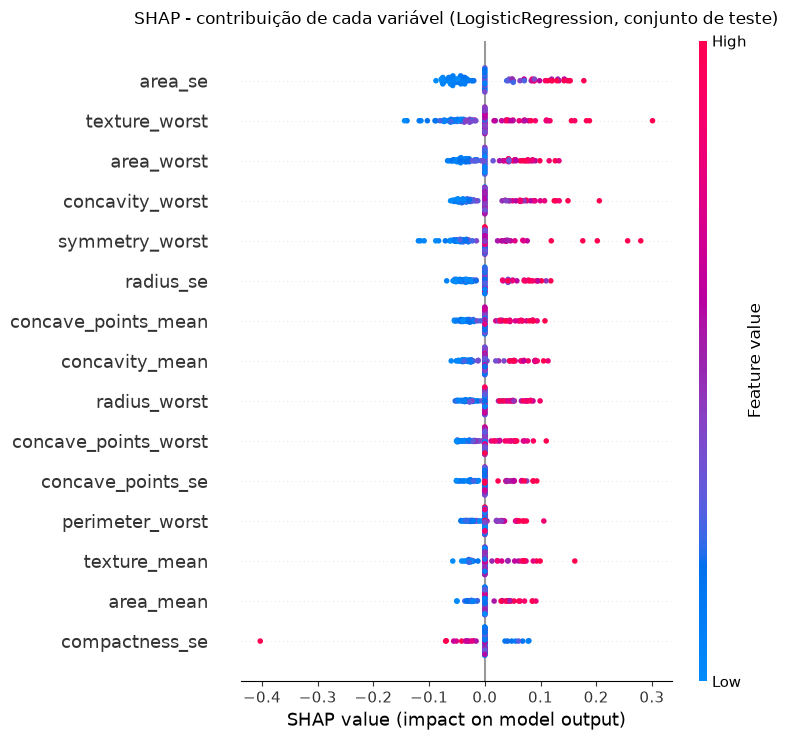

In [36]:
import shap

COLUNAS = list(x_train.columns)

# o KernelExplainer entrega arrays ao modelo; reconstruir o DataFrame mantem os
# nomes das colunas e evita o aviso do scikit-learn
def prob_maligno(dados):
    return modelo_final.predict_proba(pd.DataFrame(dados, columns=COLUNAS))[:, 1]

# O KernelExplainer e o shap.kmeans sorteiam amostras internamente. Sem semente,
# os valores mudam a cada execucao e a ordem das variaveis do 3o lugar em diante
# embaralha. Na versao 0.52 eles nao aceitam um gerador proprio e dependem da semente
# global do numpy; versoes futuras do shap podem mudar isso, por isso vale fixar a
# versao da biblioteca no pyproject.toml.
np.random.seed(RANDOM_STATE)

# comprime as 455 linhas de treino em 25 pontos representativos (reduz o custo ~18x)
fundo = shap.kmeans(x_train, 25)
explainer = shap.KernelExplainer(prob_maligno, fundo)
shap_values = explainer.shap_values(x_test, nsamples=200, silent=True)

print(f'SHAP values calculados: {shap_values.shape[0]} exames x {shap_values.shape[1]} variáveis')

shap.summary_plot(shap_values, x_test, max_display=15, show=False,
                  rng=np.random.default_rng(RANDOM_STATE))
plt.title(f'SHAP - contribuição de cada variável ({MODELO_ESCOLHIDO}, conjunto de teste)',
          fontsize=12, pad=12)
plt.tight_layout()
plt.show()

Cada ponto é um exame. A posição horizontal mostra o quanto a variável empurrou aquela
previsão (direita = para maligno) e a cor indica se o valor era alto (vermelho) ou baixo
(azul).

**Só as duas primeiras posições do ranking são estáveis.** O `KernelExplainer` estima os
valores SHAP por amostragem, e testando várias sementes (o teste está no guia
`group-infos/04_decisoes_de_modelagem_explicado.ipynb`, seção 16) `area_se` fica sempre em primeiro
e `texture_worst` sempre em segundo. Da terceira posição em diante — `symmetry_worst`,
`concavity_worst`, `area_worst` e `radius_se` — a ordem muda de uma execução para outra,
porque as diferenças entre elas estão dentro da margem de erro da estimativa. Por isso
tratamos esse grupo como um bloco, sem ordenação interna.

Em todas elas o padrão é o esperado: valores altos (vermelho) ficam à direita, empurrando
a previsão para maligno.

Chama atenção que `area_se` lidere. Ela mede a **variabilidade** da área entre os núcleos
de um mesmo exame, não o tamanho em si, ou seja, o modelo se apoia tanto na
heterogeneidade das células quanto nas medidas absolutas. É também a variável mais
assimétrica da base (assimetria de 5,4) e a que tem mais outliers pelo critério IQR, 65,
segundo o notebook `01_data_inspection.ipynb`, outliers que optamos por manter.

A tabela abaixo confronta o ranking do SHAP com a `permutation_importance` do
scikit-learn, que mede a queda de desempenho ao embaralhar cada coluna, medida de duas
formas: pela queda do recall e pela queda da AUC.

,SHAP (|valor| médio),Permutação (queda de recall),Permutação (queda de AUC)
area_se,0.0571,-0.0000,0.0075
texture_worst,0.0448,0.0476,0.0073
area_worst,0.0365,0.0167,0.0031
concavity_worst,0.0337,0.0452,0.0090
symmetry_worst,0.0328,0.0429,0.0134
radius_se,0.0322,-0.0095,0.0019
concave_points_mean,0.0264,0.0167,0.0032
concavity_mean,0.0252,0.0167,0.0038
radius_worst,0.0232,0.0143,0.0022
concave_points_worst,0.0176,0.0286,0.0034


Os 15 exames com maior contribuição de area_se: 15 malignos
   probabilidade prevista nesses exames: mínima 0.883 | mediana 1.000
   parcela da importância SHAP de area_se concentrada neles: 30.6%

Importância de area_se pelo recall, repetição a repetição: [ 0.     0.     0.     0.024  0.024  0.024 -0.024 -0.024  0.    -0.024]
   recall cai em 3 | sobe em 3 | não muda em 4 | média -0.0000
   maligno perdido no corte 0,5: exame 73 | area_se no percentil 46% do treino
   maligno perdido no corte 0,5: exame 190 | area_se no percentil 63% do treino


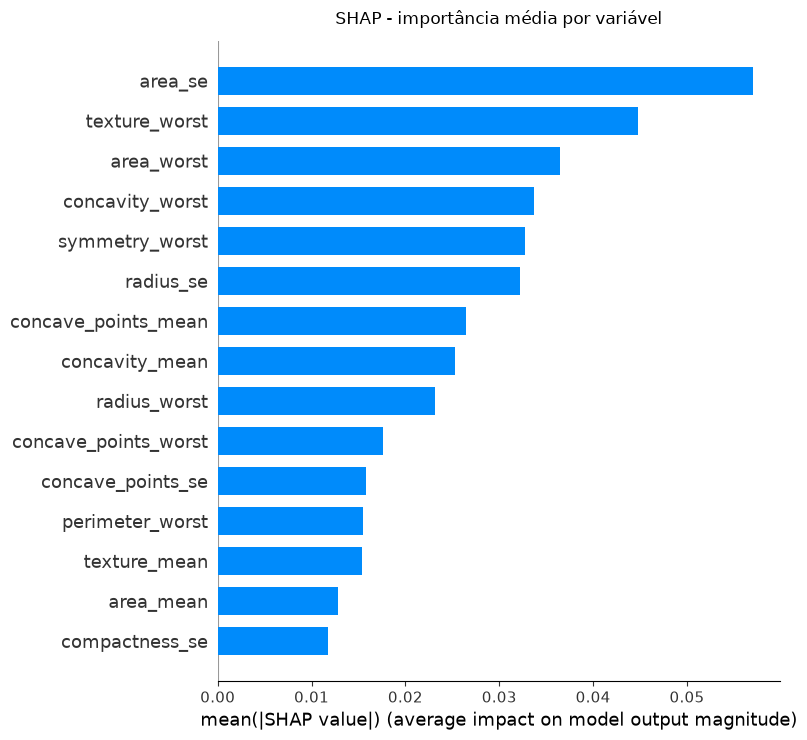

In [37]:
from sklearn.inspection import permutation_importance

imp_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=x_test.columns)

resultado_perm, imp_perm = {}, {}
for metrica in ['recall', 'roc_auc']:
    resultado_perm[metrica] = permutation_importance(modelo_final, x_test, y_test, n_repeats=10,
                                                     random_state=RANDOM_STATE, scoring=metrica, n_jobs=-1)
    imp_perm[metrica] = pd.Series(resultado_perm[metrica].importances_mean, index=x_test.columns)

ranking = pd.DataFrame({
    'SHAP (|valor| médio)': imp_shap.round(4),
    'Permutação (queda de recall)': imp_perm['recall'].round(4),
    'Permutação (queda de AUC)': imp_perm['roc_auc'].round(4),
}).sort_values('SHAP (|valor| médio)', ascending=False).head(10)
display(ranking)

# onde area_se pesa: os exames com maior contribuição SHAP dela
contrib_area = pd.Series(shap_values[:, COLUNAS.index('area_se')], index=x_test.index)
top15 = contrib_area.abs().sort_values(ascending=False).index[:15]
pos15 = [x_test.index.get_loc(i) for i in top15]
print(f'Os 15 exames com maior contribuição de area_se: {int(y_test.loc[top15].sum())} malignos')
print(f'   probabilidade prevista nesses exames: mínima {prob_teste[pos15].min():.3f} '
      f'| mediana {np.median(prob_teste[pos15]):.3f}')
print(f'   parcela da importância SHAP de area_se concentrada neles: '
      f'{contrib_area.abs().loc[top15].sum() / contrib_area.abs().sum():.1%}')

# a importância de area_se pelo recall em cada uma das 10 repetições
# (os mesmos sorteios que produziram a média da tabela)
reps = resultado_perm['recall'].importances[COLUNAS.index('area_se')]
print(f'\nImportância de area_se pelo recall, repetição a repetição: {np.round(reps, 3)}')
print(f'   recall cai em {int((reps > 1e-9).sum())} | sobe em {int((reps < -1e-9).sum())} '
      f'| não muda em {int(np.isclose(reps, 0).sum())} | média {reps.mean():.4f}')

# os únicos malignos que podem "passar a ser detectados" são os perdidos no corte de 0,5
perdidos_05 = y_test.index[(y_test == 1) & (modelo_final.predict(x_test) == 0)]
for idx in perdidos_05:
    print(f'   maligno perdido no corte 0,5: exame {idx} | area_se no percentil '
          f'{(x_train["area_se"] < x_test.loc[idx, "area_se"]).mean():.0%} do treino')

shap.summary_plot(shap_values, x_test, plot_type='bar', max_display=15, show=False,
                  rng=np.random.default_rng(RANDOM_STATE))
plt.title('SHAP - importância média por variável', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

**Os métodos concordam em parte, e a divergência tem explicação.**

`texture_worst`, `symmetry_worst` e `concavity_worst` aparecem entre as primeiras pelo
SHAP e pelas duas versões da permutação.

`area_se` é o caso que chama atenção: maior valor SHAP, importância **zero** pela
permutação do recall, mas entre as primeiras pela permutação da AUC. A diferença vem do
que cada métrica registra.

A permutação pelo recall usa o corte padrão de 0,5 e só conta decisões que mudam. A saída
acima mostra duas coisas.

Primeiro, onde `area_se` pesa: os 15 exames em que ela mais contribui são todos malignos
e já recebem probabilidade alta, então embaralhá-la raramente os leva abaixo do corte.

Segundo, que as decisões que mudam vão **nos dois sentidos**. Nas 10 repetições que
produziram a média da tabela, o recall cai em 3, sobe em 3 e não muda em 4 e a média
dá exatamente zero. Quando o recall sobe, são malignos antes perdidos que passam a ser
detectados; no corte de 0,5 os únicos nessa condição são os exames 73 e 190, que têm
`area_se` em valores medianos (percentis 46 e 63 do treino). O sorteio frequentemente lhes
atribui um valor maior, típico de tumor maligno, e eles cruzam o corte.

Cada repetição move o recall em ±0,024 por causa de um único exame. É o retrato de uma
medida instável: o zero da tabela não diz que `area_se` é irrelevante, diz que ganhos e
perdas se anularam naquele sorteio. A AUC, que reage a qualquer mudança no ordenamento
das probabilidades, registra a perda.

**A colinearidade entra por outra porta.** É comum ler que a permutação subestima
variáveis correlacionadas "porque o modelo recorre à gêmea". Num modelo já treinado isso
não acontece: os pesos estão fixos e embaralhar uma coluna remove a contribuição dela por
inteiro. O efeito da colinearidade acontece antes, no treino. Como `area_se`, `radius_se`
(correlação de 0,95) e `perimeter_se` carregam quase a mesma informação, o modelo
regularizado divide o peso entre as três, e cada uma recebe menos do que receberia
sozinha. O guia (seção 17) demonstra isso retreinando o modelo sem as gêmeas.

Conclusão prática: **para medir importância, a permutação pela AUC é mais informativa que
pelo recall**. E nenhum método é o certo isoladamente: SHAP, coeficientes e permutação são
leituras diferentes do mesmo modelo, não evidências independentes.

### Coeficientes da regressão logística

O SHAP responde *quanto* cada variável pesa. Um modelo linear responde também **em que
direção**: o coeficiente diz quantas unidades de log-odds a previsão se desloca quando a
variável aumenta **um IQR**, e o sinal indica para qual classe. A unidade é o IQR porque
o `RobustScaler`, escolhido pelo GridSearch para este modelo, centraliza cada variável
pela mediana e a divide pelo intervalo interquartil.

Como o modelo final é a regressão logística, esta é a explicação **direta** da decisão,
não uma aproximação. Os coeficientes são lidos do pipeline já tunado pelo GridSearch.

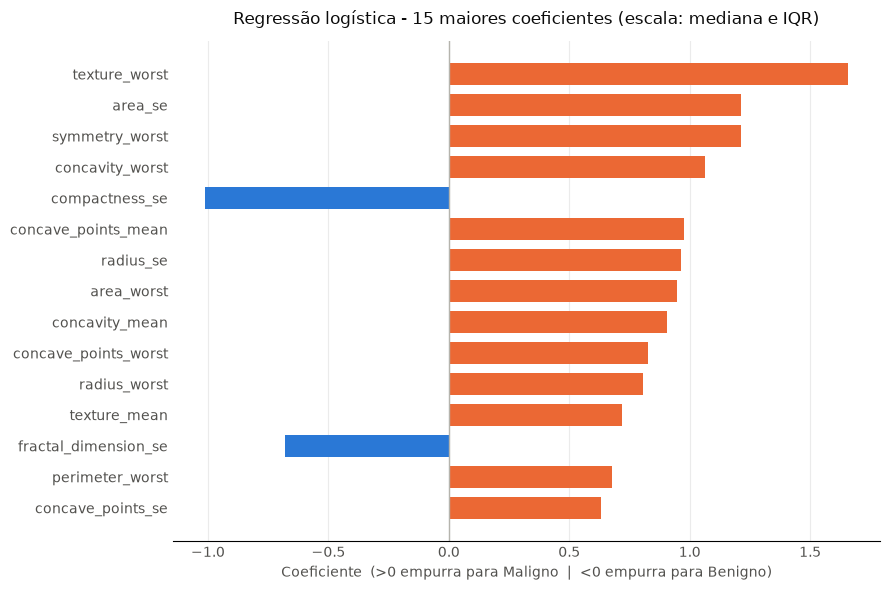

Top 8 por |coeficiente|:
texture_worst          1.656
area_se                1.214
symmetry_worst         1.211
concavity_worst        1.063
compactness_se        -1.012
concave_points_mean    0.978
radius_se              0.963
area_worst             0.947


In [38]:
logreg = melhores['LogisticRegression']
coeficientes = pd.Series(logreg.named_steps['clf'].coef_[0], index=x_train.columns)

top = coeficientes.sort_values(key=abs, ascending=False).head(15).iloc[::-1]
cores = [LARANJA if c > 0 else AZUL for c in top]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=cores, height=.7)
ax.axvline(0, color='#b5b4ad', lw=1)
ax.set_xlabel('Coeficiente  (>0 empurra para Maligno  |  <0 empurra para Benigno)',
              color=TINTA2)
ax.set_title('Regressão logística - 15 maiores coeficientes (escala: mediana e IQR)',
             fontsize=12, pad=12, color=TINTA)
ax.grid(axis='x', alpha=.25); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
ax.tick_params(colors=TINTA2, length=0)
plt.tight_layout()
plt.show()

print('Top 8 por |coeficiente|:')
print(coeficientes.sort_values(key=abs, ascending=False).head(8).round(3).to_string())

**`texture_worst` é a variável mais consistente entre as leituras.** É a primeira em
coeficiente (1,656), a segunda no SHAP e está entre as quatro primeiras nas duas versões
da permutação (1ª pelo recall, 4ª pela AUC). É a única que fica entre as quatro primeiras
em todas as leituras de forma estável: `concavity_worst` também aparece com a semente
usada aqui, mas no SHAP sua posição oscila entre a 4ª e a 6ª conforme a semente.

Vale a precisão: coeficientes, SHAP e permutação **não são evidências independentes** —
são leituras diferentes do mesmo modelo treinado. A convergência mostra que a importância
de `texture_worst` não é artefato de um método específico, mas não substitui uma
validação com dados externos.

E chama atenção porque sua correlação linear com o alvo é modesta (0,46, contra 0,79 de
`concave_points_worst`): o peso vem de contribuições que o coeficiente de Pearson, olhando
uma variável de cada vez, não enxerga.

**Coeficientes negativos exigem cautela.** Algumas variáveis aparecem empurrando para
benigno, o que contraria a leitura clínica esperada. Em presença de multicolinearidade
isso é comum: o modelo usa uma variável para corrigir o excesso introduzido pela gêmea
correlacionada, o chamado efeito supressor. Com 21 pares acima de 0,90 nesta base, o
sinal de um coeficiente isolado não deve ser interpretado como relação causal.

Vale a ressalva geral: coeficientes e valores SHAP descrevem **o comportamento do
modelo**, não a biologia do tumor.

### Explicando um caso individual

O SHAP também decompõe uma previsão isolada. Abaixo analisamos, entre os tumores
malignos que o modelo **não** detectou, aquele que ficou mais perto da fronteira de
decisão, o caso que melhor mostra o que está em jogo na escolha do limiar.

O gráfico parte de `E[f(X)]`, a probabilidade média do modelo, e mostra cada variável
somando ou subtraindo até chegar em `f(x)`, a previsão daquele exame.

Malignos não detectados com o limiar 0.35: 2
   exame  190 | probabilidade prevista 0.3352
   exame   73 | probabilidade prevista 0.1052

Com o limiar mais agressivo entre os equivalentes (0.15):
   malignos a mais detectados: 1
   falsos positivos a mais:    5

Exame detalhado abaixo: índice 190 (probabilidade 0.3352)


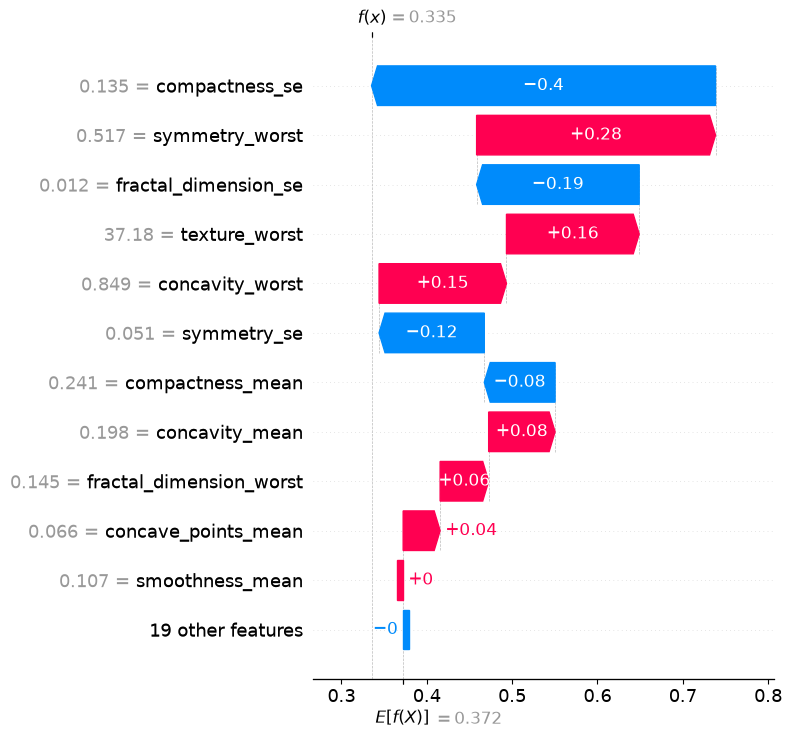

In [39]:
# Entre os malignos que o modelo deixa passar, analisamos o que ficou MAIS PERTO
# da fronteira: é o caso que melhor ilustra o efeito da escolha do limiar.
mal_perdidos = np.where((y_test.values == 1) & (prob_teste < LIMIAR))[0]
alvo = int(mal_perdidos[np.argmax(prob_teste[mal_perdidos])])

print(f'Malignos não detectados com o limiar {LIMIAR:g}: {len(mal_perdidos)}')
for i in sorted(mal_perdidos, key=lambda j: -prob_teste[j]):
    print(f'   exame {x_test.index[i]:4d} | probabilidade prevista {prob_teste[i]:.4f}')

faixa = (prob_teste >= LIMIAR_AGRESSIVO) & (prob_teste < LIMIAR)
print(f'\nCom o limiar mais agressivo entre os equivalentes ({LIMIAR_AGRESSIVO:g}):')
print(f'   malignos a mais detectados: {int(((y_test.values == 1) & faixa).sum())}')
print(f'   falsos positivos a mais:    {int(((y_test.values == 0) & faixa).sum())}')

print(f'\nExame detalhado abaixo: índice {x_test.index[alvo]} '
      f'(probabilidade {prob_teste[alvo]:.4f})')

ex = shap.Explanation(values=shap_values[alvo],
                      base_values=explainer.expected_value,
                      data=x_test.iloc[alvo].values,
                      feature_names=list(x_test.columns))
shap.plots.waterfall(ex, max_display=12, show=False)
plt.tight_layout()
plt.show()

**O caso que escapou por pouco.** Dos dois malignos não detectados, um recebeu
probabilidade 0,105 — bem longe da fronteira, um erro que nenhum limiar razoável
corrigiria. O outro ficou em 0,335, a **0,015 do corte de 0,35**.

Esse segundo caso é o preço concreto da regra de decisão adotada. O limiar de 0,15, o
mais agressivo entre os equivalentes, e também o de menor custo médio, o teria detectado,
ao custo de 5 falsos positivos a mais neste conjunto de teste. Não o adotamos porque, com
`CUSTO_FN = 10`, os limiares de 0,15 a 0,35 são estatisticamente equivalentes, e a regra
de 1 erro-padrão manda ficar com o mais conservador.

E, sobretudo, porque essa escolha foi feita na validação cruzada. Trocar para 0,15 *agora*,
depois de ver que ele recupera este exame, seria deixar o conjunto de teste influenciar a
decisão, exatamente o vazamento que o notebook inteiro procura evitar.

O waterfall mostra quais variáveis puxaram a previsão para baixo neste exame. É o tipo de
leitura que permite a um especialista decidir se concorda com o modelo caso a caso.

Vale registrar a limitação: os valores SHAP explicam **como o modelo decide**, não
estabelecem causalidade clínica.

### Persistência do modelo

O pipeline é salvo inteiro, scaler incluído, de modo que a inferência futura recebe
dados crus e aplica a mesma padronização aprendida no treino. As métricas e os
hiperparâmetros escolhidos vão num JSON ao lado, para que o resultado seja rastreável
sem reexecutar o notebook.

In [40]:
import joblib, json, sklearn
from pathlib import Path
from sklearn.model_selection import cross_validate

Path('../models/tuned').mkdir(parents=True, exist_ok=True)
Path('../models/metrics').mkdir(parents=True, exist_ok=True)

caminho_modelo = f'../models/tuned/{MODELO_ESCOLHIDO.lower()}_tuned.joblib'
joblib.dump(modelo_final, caminho_modelo)

# hiperparâmetros: só os que o GridSearch ajustou, como valores (não como texto do repr)
escala = modelo_final.named_steps['scaler']
classificador = modelo_final.named_steps['clf']
ajustados = [k.split('__', 1)[1] for k in CONFIGS[MODELO_ESCOLHIDO][1] if k.startswith('clf__')]

# validação cruzada no ponto de operação: as mesmas 20 repetições usadas para escolher o limiar
j_lim = max(equivalentes)
recall_cv = 1 - fn_rep.mean(axis=0)[j_lim] / n_mal
espec_cv = 1 - fp_rep.mean(axis=0)[j_lim] / n_ben

# AUC não depende do limiar; vem de uma única validação cruzada de 5 folds
auc_cv = cross_validate(modelo_final, x_train, y_train, cv=cv, scoring='roc_auc')['test_score']

# teste: as três taxas com intervalo de confiança de Wilson
vn = int(((y_test == 0) & (y_pred_final == 0)).sum())
n_benignos_teste = int((y_test == 0).sum())
lo_e, hi_e = intervalo_wilson(vn, n_benignos_teste)

metricas = {
    'modelo': MODELO_ESCOLHIDO,
    'pipeline': {
        'scaler': escala if isinstance(escala, str) else type(escala).__name__,
        'classificador': type(classificador).__name__,
        'hiperparametros_ajustados': {p: classificador.get_params()[p] for p in ajustados},
    },
    'decisao': {
        'limiar': LIMIAR,
        'custo_fn': CUSTO_FN,
        'regra': 'mínimo custo esperado (CUSTO_FN x FN + FP), com regra de 1 erro-padrão',
    },
    'validacao_cruzada_treino': {
        'no_limiar': {
            'limiar': LIMIAR,
            'recall': float(recall_cv),
            'especificidade': float(espec_cv),
            'folds': 5,
            'repeticoes': N_REPETICOES,
        },
        'auc': {
            'media': float(auc_cv.mean()),
            'desvio': float(auc_cv.std()),
            'folds': 5,
            'repeticoes': 1,
        },
    },
    'teste': {
        'limiar': LIMIAR,
        'recall': float(recall_score(y_test, y_pred_final)),
        'recall_ic95_wilson': [float(lo_r), float(hi_r)],
        'especificidade': vn / n_benignos_teste,
        'especificidade_ic95_wilson': [float(lo_e), float(hi_e)],
        'precisao': float(precision_score(y_test, y_pred_final)),
        'precisao_ic95_wilson': [float(lo_p), float(hi_p)],
        'auc': float(roc_auc_score(y_test, prob_teste)),
    },
    'reproducao': {
        'arquivo_de_dados': DATA_PATH,
        'random_state': RANDOM_STATE,
        'divisao': {'proporcao_teste': 0.2, 'estratificada': True,
                    'n_treino': int(len(y_train)), 'n_teste': int(len(y_test))},
        'versoes': {'python': __import__('platform').python_version(),
                    'scikit-learn': sklearn.__version__, 'numpy': np.__version__,
                    'pandas': pd.__version__},
    },
}
with open('../models/metrics/metricas_validacao.json', 'w', encoding='utf-8') as f:
    json.dump(metricas, f, indent=2, ensure_ascii=False)

print(f'Modelo salvo em {caminho_modelo}')
print(json.dumps(metricas, indent=2, ensure_ascii=False))

Modelo salvo em ../models/tuned/logisticregression_tuned.joblib
{
  "modelo": "LogisticRegression",
  "pipeline": {
    "scaler": "RobustScaler",
    "classificador": "LogisticRegression",
    "hiperparametros_ajustados": {
      "C": 1,
      "class_weight": "balanced"
    }
  },
  "decisao": {
    "limiar": 0.35,
    "custo_fn": 10,
    "regra": "mínimo custo esperado (CUSTO_FN x FN + FP), com regra de 1 erro-padrão"
  },
  "validacao_cruzada_treino": {
    "no_limiar": {
      "limiar": 0.35,
      "recall": 0.9729411764705882,
      "especificidade": 0.9615789473684211,
      "folds": 5,
      "repeticoes": 20
    },
    "auc": {
      "media": 0.995252837977296,
      "desvio": 0.004491239452422903,
      "folds": 5,
      "repeticoes": 1
    }
  },
  "teste": {
    "limiar": 0.35,
    "recall": 0.9523809523809523,
    "recall_ic95_wilson": [
      0.8421014760304114,
      0.9868424750910944
    ],
    "especificidade": 0.9861111111111112,
    "especificidade_ic95_wilson": [
    